# [이론] 토픽 모델링 — 임베딩 군집으로 찾는 주제

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 토픽 모델링은 무엇에 답하는가

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 비정형 데이터(자연어)</div>
<h1 style="color:#000000;margin:10px 0">토픽 모델링 — 임베딩 군집으로 찾는 주제</h1>
<div style="font-size:1.05em;color:#656565">라벨이 없는 민원 2만 건에 어떤 주제가 몇 % 씩 있는지 토픽 표로 답하고 최소 군집 크기와 이상치(−1)가 그 비율을 어떻게 바꾸는지 확인합니다</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)는 선택입니다.

### 핵심 질문: 민원에는 어떤 주제가 몇 % 씩 있는가 [필수]

공정거래위원회에 2020년 1～10월 접수된 소비자 민원을 다룹니다. 약 50만 건 가운데 무작위로 고른 2만 건이 이 수업의 표본입니다. 민원 한 건이 문서 하나이고, 분석하는 글은 그 민원의 제목(원자료 열 「사건제목」)입니다.

문서 비율 · TF-IDF · 문장 임베딩 검색은 찾을 단어나 비교할 두 집단, 쿼리 문장을 먼저 정해야 쓸 수 있습니다. 민원에 어떤 주제가 있는지 물을 때는 셋 가운데 무엇도 아직 정할 수 없습니다.

> 찾을 단어도 쿼리도 없이, 민원 2만 건의 주제와 그 비율을 알 수 있는가?

- 민원 3건 가운데 2건은 뜻이 가까운 민원끼리 토픽(주제) 40개로 나뉩니다. 나머지 1건은 어느 토픽에도 속하지 않은 이상치이고, 토픽 번호는 −1 입니다.
- 가장 큰 토픽 0 도 전체 민원의 7.63% 라서 주제가 한두 가지에 몰려 있지 않습니다. 토픽 0 에 많이 나오고 다른 토픽에는 드문 단어(상위 단어)는 개통 · 요금 · 휴대폰입니다.
- 비율은 모두 이상치까지 포함한 민원 2만 건을 기준으로 계산합니다. 토픽 40개의 비율을 더하면 100% 가 아니라 66.95% 이고, 나머지 33.05% 가 이상치입니다.
- 토픽 수 40 은 분석가가 최소 군집 크기를 100 으로 정해서 나온 수입니다. 최소 군집 크기는 토픽으로 인정할 군집의 최소 민원 수이고, 이 값을 바꾸면 토픽 수와 이상치 비율이 함께 바뀝니다.

### 토픽 모델링이란 무엇인가 [필수]

**토픽 모델링(topic modeling)** 은 뜻이 가까운 글끼리 군집으로 나눠, 군집 하나를 주제 하나로 다루는 방법입니다. 이 수업에서는 민원 사이의 가까움을 문장 임베딩으로 계산합니다. 결과는 민원마다 배정되는 토픽 번호와 토픽 표입니다.

```text
민원 20,000건
  ↓ 민원마다 문장 임베딩(1,024차원 벡터)
  ↓ 벡터가 가까운 민원끼리 군집으로 나눔
결과 1: 민원마다 토픽 번호 하나(0, 1, 2 … 또는 −1)
결과 2: 토픽마다 건수 · 비율 · 상위 단어 · 대표 문서를 정리한 토픽 표
```

**토픽 번호는 무엇인가요?**

**토픽 번호** 는 같은 군집의 민원에 똑같이 배정되는 번호입니다. 건수가 많은 토픽부터 0, 1, 2 … 차례로 매기고, 어느 토픽에도 속하지 않은 민원만 −1 입니다.

| 민원 | 토픽 번호 |
|---|---:|
| 개통하지 않은 휴대폰 요금 지출에 관한 건 | 0 |
| 국외여행 계약 후 취소 항공 수수료 과다청구 | 1 |
| 화장품 반품 거부하여 문의 | −1 |

민원마다 번호가 하나씩 있으므로 접수일자 · 품목 · 연령대와 함께 집계할 수 있습니다.

토픽 번호를 색으로 칠하면 어떻게 보이는지 토픽 모델링 도구 BERTopic 의 공식 설명서 그림으로 봅니다.

<img src="https://maartengr.github.io/BERTopic/getting_started/visualization/datamapplot.png" alt="회색 점이 넓게 깔린 2차원 그림에 색 군집 스무 개 남짓과 영어 토픽 이름이 선으로 이어져 있다" width="560" height="560"/>
<p align="center"><em>▲ 점 하나가 문서 하나이고, 기계학습을 다룬 문서들이다. 뜻이 가까운 문서는 대체로 가까이 있지만 가로 · 세로 위치 자체에는 뜻이 없다. 같은 토픽의 문서는 같은 색이고 토픽마다 영어 이름이 선으로 이어져 있다. 어느 토픽에도 속하지 않은 문서(−1)는 회색이다 (출처: BERTopic 설명서 「Visualize Documents」 DataMapPlot, Maarten Grootendorst, MIT)</em></p>

**토픽 표에는 무엇이 있나요?**

**토픽 표** 는 토픽마다 건수 · 비율 · 상위 단어 · 대표 문서를 정리한 표입니다. 대표 문서는 토픽 안에서 상위 단어에 가장 잘 맞는 민원 한 건이고, 고르는 계산은 「4. 토픽 표는 어떻게 읽는가」에서 다룹니다. 아래는 민원 2만 건의 토픽 표에서 가장 큰 토픽 2개와 이상치입니다.

| 토픽 | 건수 | 비율 | 상위 단어(3개) | 대표 문서 |
|---:|---:|---:|---|---|
| 0 | 1,525 | 7.63% | 개통 · 요금 · 휴대폰 | 개통하지 않은 휴대폰 요금 지출에 관한 건 |
| 1 | 1,484 | 7.42% | 여행 · 항공 · 취소 | 국외여행 계약 후 취소 항공 수수료 과다청구 |
| −1 | 6,610 | 33.05% | | |

이상치는 서로 다른 주제의 민원이 함께 있어 상위 단어와 대표 문서를 비워 둡니다. 토픽 표에는 그림의 영어 이름 같은 토픽 이름도 없습니다. 이름은 분석가가 상위 단어와 원문을 읽고 정합니다.

**토픽 모델링은 분석 전에 무엇을 정하나요?**

앞에서 배운 방법과 비교하면, 먼저 정하는 것이 다릅니다.

| 방법 | 묻는 질문 | 먼저 정한 것 | 결과 |
|---|---|---|---|
| 문서 비율 | 이 단어를 쓴 글은 몇 % 인가 | 찾을 단어와 품사 선택 | 단어마다 문서 비율 |
| TF-IDF · 가중 로그 오즈 | 두 집단은 어떤 단어가 다른가 | 비교할 두 집단 | 집단 특징 단어 |
| 문장 임베딩 · 코사인 | 이 글과 가까운 글은 무엇인가 | 쿼리 문장과 임계값 | 쿼리와 가까운 글 목록 |
| 토픽 모델링(임베딩 기반 군집화) | 어떤 주제가 몇 % 씩 있는가 | 최소 군집 크기(100) | 민원마다 토픽 번호와 토픽 표 |

토픽 모델링에서는 찾을 단어나 비교할 집단, 쿼리 문장 대신 최소 군집 크기를 먼저 정합니다. 최소 군집 크기를 100 에서 150 으로 키우면 토픽 수가 40개에서 28개로 줄어듭니다.

<div class="lms-summary">

**정리**

토픽 모델링은 찾을 단어나 쿼리 없이, 문장 임베딩이 서로 가까운 민원끼리 군집으로 나눕니다. 결과는 민원마다 배정된 토픽 번호와, 토픽마다 건수 · 비율 · 상위 단어 · 대표 문서를 정리한 토픽 표입니다.

분석가는 찾을 단어 대신 최소 군집 크기를 먼저 정하고, 이 값에 따라 토픽 수가 달라집니다.

</div>

## 1. 토픽과 이상치(−1)

민원 2만 건에서 무엇을 주제 하나로 볼까요? 문장 임베딩 벡터가 가까운 민원끼리 모인 군집 하나를 토픽 하나로 봅니다. 어느 군집에도 속하지 않은 민원은 이상치(−1)가 되고, 민원 3건 가운데 1건이 이상치입니다.

### 토픽이란 무엇인가 [필수]

문장 임베딩을 배울 때 문장 인코더 KURE-v1 로 문장 하나를 1,024차원 벡터로 바꿨습니다. 1,024차원은 벡터를 이루는 수가 1,024개라는 뜻입니다. 뜻이 가까운 두 민원은 단어가 겹치지 않아도 벡터가 가깝습니다.

**토픽(topic)** 은 같은 주제를 다룬 민원들의 군집 하나입니다. 같은 토픽의 민원은 문장 임베딩 벡터가 서로 가깝습니다.

가장 큰 토픽 0 의 민원 3건과, 어느 토픽에도 속하지 않은 민원 1건입니다.

| 민원 | 토픽 |
|---|---|
| 개통하지 않은 휴대폰 요금 지출에 관한 건 | 토픽 0 |
| 휴대폰 교체후 발생한 과다 위약금 피해건. | 토픽 0 |
| 기기값 과다청구로인한철회요청 | 토픽 0 |
| 화장품 반품 거부하여 문의 | 어느 토픽에도 속하지 않음 |

토픽 0 의 세 민원은 쓴 단어가 달라도 모두 휴대폰 요금 · 계약 이야기라 한 토픽이 됩니다. 「화장품 반품 거부하여 문의」는 벡터가 가까운 민원이 충분히 모여 있지 않아 어느 토픽에도 속하지 않습니다.

그래서 토픽을 찾을 때는 어느 토픽에도 속하지 않는 민원을 어떻게 다룰지도 정해야 합니다.

**밀도가 높은 영역 밖의 민원은 어떻게 되나요?**

필수 머신러닝에서 배운 DBSCAN 은 초승달 데이터 400점에서 반경(eps) 안의 이웃 수로 점마다 밀도를 계산했습니다. 이웃이 충분한 점이 이어진 영역만 군집으로 남기고, 어디에도 속하지 않은 점은 −1(잡음)이 됐습니다.

**밀도 기반 군집화(density-based clustering)** 는 이렇게 밀도가 높은 영역만 군집으로 남기는 방법입니다. 토픽을 찾는 HDBSCAN 도 밀도 기반 군집화이고, 반경 대신 최소 군집 크기를 정합니다. HDBSCAN 이 군집을 고르는 방법은 「2. BERTopic 은 어떻게 토픽을 찾는가」에서 다룹니다.

**이상치(−1)는 무엇인가요?**

**이상치(−1)** 는 어느 토픽에도 속하지 않은 민원입니다. 「화장품 반품 거부하여 문의」처럼 가까운 민원이 충분히 모여 있지 않은 민원이 이상치가 됩니다.

BERTopic 설명서는 이런 민원을 outlier(이상치)라고 부릅니다. DBSCAN 의 잡음(−1)과 같은 것이고, 통계에서 흔히 말하는 극단값이라는 뜻은 아닙니다.

아래 그림은 hdbscan 설명서에 있는 작은 예입니다. 점은 민원이 아니라 설명서가 만든 예시 자료이고, 회색 점이 이상치입니다.

<img src="https://hdbscan.readthedocs.io/en/latest/_images/how_hdbscan_works_20_1.png" alt="초록·빨강·파랑 세 군집과 회색 점 몇 개가 있는 산점도" width="560" height="386" />
<p align="center"><em>▲ 가로 · 세로는 점의 위치다. HDBSCAN 으로 초록 · 빨강 · 파랑 군집 3개가 나뉘고, 회색 점 몇 개는 어느 군집에도 속하지 않은 이상치다 (출처: hdbscan 설명서 「How HDBSCAN Works」, Leland McInnes 외, BSD-3-Clause)</em></p>

**민원 2만 건은 어떻게 나뉘었나요?**

민원 2만 건도 HDBSCAN 으로 나눴습니다. 아래 2차원 그림은 민원마다 만든 1,024차원 벡터를 UMAP 으로 2차원까지 줄여 그린 그림입니다. UMAP 은 가까운 이웃 관계가 남도록 차원을 줄이는 방법이고, 동작은 「2. BERTopic 은 어떻게 토픽을 찾는가」에서 다룹니다.

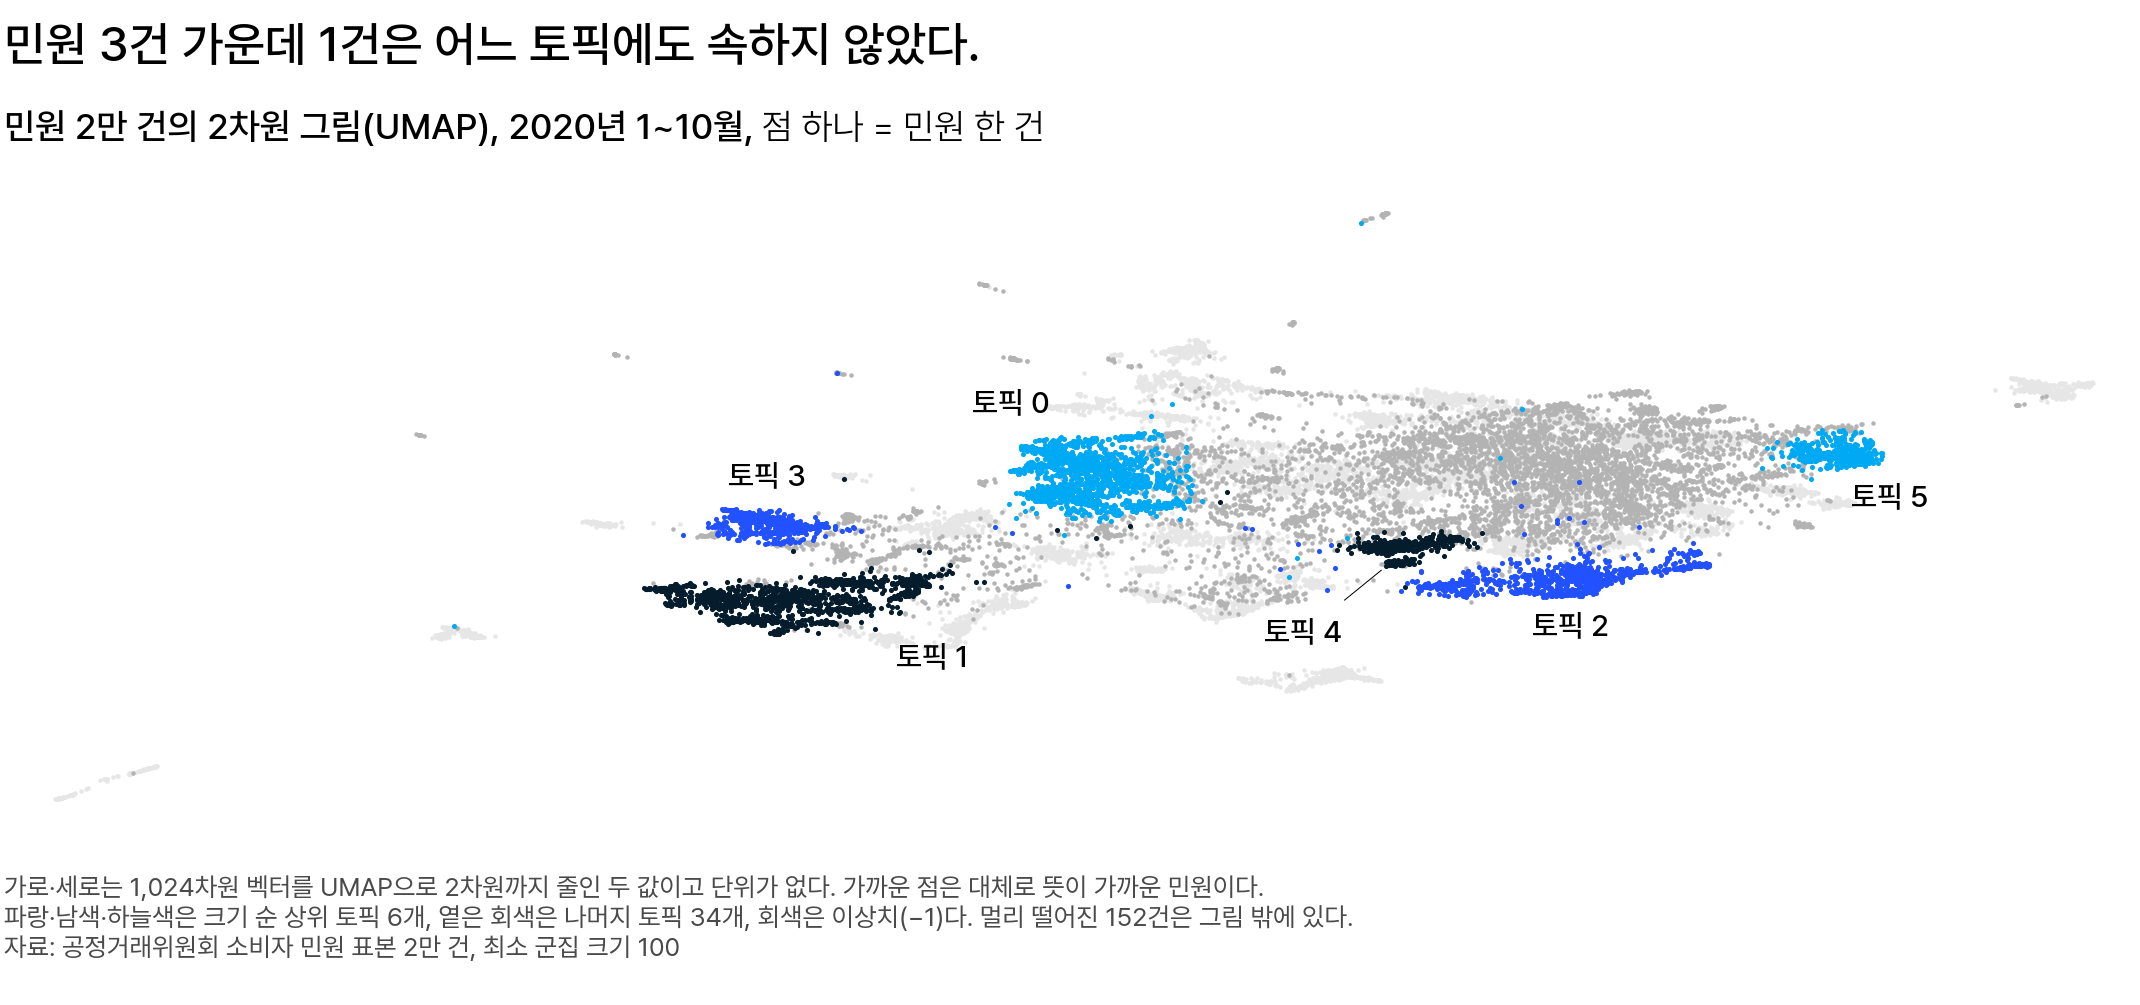

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 점 하나가 민원 한 건이다. 가로 · 세로는 1,024차원 벡터를 UMAP 으로 2차원까지 줄인 두 값이다. 파랑 · 남색 · 하늘색은 크기가 큰 토픽 6개이고, 옅은 회색은 나머지 토픽, 회색은 이상치(−1)다</em></p>

토픽에 속한 민원은 13,390건이고, 이상치는 6,610건(33.05%)으로 민원 3건 가운데 1건입니다.

큰 토픽 6개(토픽 0～5)는 저마다 한곳에 모여 있습니다. 나머지 토픽도 최소 군집 크기를 100 으로 정했으므로 모두 100건 이상입니다.

회색 이상치는 그림의 넓은 영역에서 여러 토픽 사이사이에 있습니다. 2차원 그림에서도 뜻이 가까운 민원은 대체로 가까이 그려집니다. 다만 차원을 크게 줄이면 거리와 밀도가 그대로 남지 않아, 그림에서 이웃한 두 점도 다른 토픽이거나 이상치일 수 있습니다.

### 왜 모든 민원을 토픽에 배정하지 않는가 [필수]

모든 민원에 토픽 번호가 하나씩 있으면 토픽 비율의 합이 100% 가 되어 표가 깔끔합니다. 필수 머신러닝의 K-Means 로 토픽을 만들면 모든 민원이 토픽 번호를 하나씩 받습니다. K-Means 는 모든 민원을 가장 가까운 중심에 배정하고, 어느 군집에도 속하지 않는다는 선택지가 없습니다.

**K-Means 와 밀도 기반 군집화의 결과는 어떻게 다른가요?**

같은 민원에 두 방법을 쓰면 토픽 수를 같게 맞춰도 토픽에 배정되는 민원이 다릅니다.

| 구분 | K-Means | 밀도 기반 군집화 |
|---|---|---|
| 토픽 수 | 분석가가 먼저 정한다 | 찾은 군집 수가 토픽 수가 된다 |
| 토픽에 배정되는 민원 | 모든 민원 | 밀도가 높은 영역의 민원만 |
| 이상치 | 없음 | 민원 3건 가운데 1건 |
| 좋은 점 | 토픽 비율의 합이 100% | 토픽마다 서로 가까운 민원만 있음 |
| 약한 점 | 밀도가 높은 영역 밖의 민원까지 가장 가까운 군집에 함께 배정됨 | 토픽 비율만 더하면 100% 가 되지 않음 |
| 이럴 때 쓴다 | 모든 민원에 토픽 번호가 하나씩 꼭 있어야 할 때 | 뚜렷한 주제만 토픽으로 나누고 나머지는 따로 볼 때 |

K-Means 에서 토픽 비율의 합이 100% 가 되는 것은 주제와 먼 민원까지 토픽에 포함하기 때문입니다. 예를 들어 이상치인 「화장품 반품 거부하여 문의」도 K-Means 에서는 가장 가까운 군집 하나에 배정됩니다. 그러면 이 민원 제목의 명사까지 그 군집의 단어 횟수에 더해져, 상위 단어에 주제와 먼 단어가 포함될 수 있습니다.

<details class="lms-extra"><summary>더 깊이 — 짧은 민원 제목에 LDA 대신 임베딩 기반 군집화를 쓰는 이유</summary>

토픽 모델링에 오래 쓰인 LDA(Latent Dirichlet Allocation)는 문서-단어 행렬의 단어 횟수로 토픽마다 단어가 나올 확률을 추정합니다. 문서 하나에 토픽이 각각 몇 % 씩 있는지도 그 문서의 단어로 추정합니다.

표본 2만 건의 민원 제목 하나에는 명사가 평균 6.11개뿐입니다. 명사 6개 남짓으로는 민원 하나 안에서 토픽을 구분할 근거가 적습니다.

반면 문장 임베딩은 단어 횟수로 확률을 추정하지 않고 민원 제목 하나를 벡터 하나로 바꿉니다. 문장 인코더는 수많은 문장으로 미리 학습된 모델이라 단어 몇 개뿐인 민원 제목도 뜻을 벡터로 나타냅니다. 그래서 짧은 민원 제목에는 LDA 대신 임베딩 기반 군집화를 씁니다.

토픽 비중 θ 와 토픽의 단어 확률 φ 를 구하는 계산과 LDA 를 쓰기에 알맞은 자료는 LDA 수업에서 자세히 다룹니다.

</details>

<div class="lms-summary">

**정리**

토픽은 같은 주제를 다룬 민원들의 군집이고, 어느 군집에도 속하지 않은 민원은 이상치(−1)가 됩니다. 모든 민원을 배정하면 주제와 먼 민원의 명사까지 단어 횟수에 더해지므로, 밀도 기반 군집화는 그런 민원을 이상치로 남깁니다.

**할 일**

- 토픽 표에는 이상치의 건수와 비율을 포함합니다

이상치 항목이 없으면 표를 보는 사람은 토픽 40개가 민원 전부라고 오해합니다.

</div>

## 2. BERTopic 은 어떻게 토픽을 찾는가

민원 2만 건에서 토픽 번호와 상위 단어는 어떤 단계를 거쳐 나올까요?

**BERTopic**(Grootendorst 2022, MIT 라이선스)은 토픽을 찾는 라이브러리입니다. 이미 있는 방법 4가지를 차례로 실행하고, 이 네 단계를 예시 문장 11개로 하나씩 따라갑니다.

### BERTopic 의 네 단계 [필수]

예시 문장 11개는 주제 3가지에 3문장씩 있고, 어느 주제에도 속하지 않는 문장이 2개 있습니다.

| 문장 | 만든 의도 |
|---|---|
| 휴대폰 요금이 약정보다 많이 청구됐어요 | 휴대폰 요금 |
| 개통하지 않은 휴대폰 요금이 나왔습니다 | 휴대폰 요금 |
| 이번 달 통신비가 두 배로 나왔어요 | 휴대폰 요금 |
| 항공사가 항공권 환불을 미루고 있어요 | 항공권 환불 |
| 항공권 취소 수수료를 과하게 뗐습니다 | 항공권 환불 |
| 결항된 항공편 환불을 받지 못했어요 | 항공권 환불 |
| 헬스장 중도 해지 위약금이 과합니다 | 헬스장 해지 |
| 헬스장 회원권 환불을 거절당했어요 | 헬스장 해지 |
| 피트니스 센터 이용권 환불을 안 해 줍니다 | 헬스장 해지 |
| 택배 상자가 찢어져서 왔어요 | 어느 주제도 아님 |
| 냉장고 문이 제대로 닫히지 않아요 | 어느 주제도 아님 |

네 단계는 앞 단계의 출력을 다음 단계의 입력으로 씁니다. 괄호 안은 예시 문장에 쓴 모델과 값입니다.

```text
예시 문장 11개
   ↓ ① 문장 임베딩(KURE-v1)
문장마다 1,024차원 벡터
   ↓ ② UMAP(이웃 3개, 5차원, 시드 0)
문장마다 5차원 벡터
   ↓ ③ HDBSCAN(최소 군집 크기 3, min_samples 2)
문장마다 토픽 번호: 0 · 1 · 2 또는 −1
   ↓ ④ c-TF-IDF(토픽마다 모은 명사)
토픽마다 상위 단어: 토픽 1 은 항공 · 환불
```

휴대폰 요금 · 항공권 환불 · 헬스장 해지 문장이 차례로 토픽 0 · 1 · 2 가 되고, 택배 · 냉장고 문장은 이상치(−1)가 됩니다.

- 토픽 번호는 ③ HDBSCAN 이 정합니다. ① · ② 는 그 입력을 만듭니다.
- 상위 단어는 배정이 끝난 뒤 ④ c-TF-IDF 가 정합니다.

미리 학습된 모델은 ① 의 문장 인코더 KURE-v1 하나뿐입니다. ②～④ 는 분석가가 지정한 값과 시드(난수 생성의 시작값)로 계산하므로, 괄호 안의 값 하나만 바뀌어도 결과가 바뀔 수 있습니다.

민원 2만 건도 같은 네 단계를 거쳤습니다. KURE-v1 · 이웃 15개 · 최소 군집 크기 100 으로 실행해 토픽 40개를 얻었습니다.

### UMAP 은 차원을 어떻게 줄이는가 [필수]

**차원은 왜 줄이나요?**

밀도 기반 군집화는 가까운 이웃이 얼마나 가까운지로 밀도를 계산합니다. 그런데 1,024차원처럼 차원이 높으면 가장 가까운 문장과 가장 먼 문장의 거리 차이가 작아지기 쉽습니다. 거리는 차원마다의 차이를 모두 더해 계산하므로, 주제와 상관없는 작은 차이도 1,024개가 모이면 커지기 때문입니다.

문장마다 가장 먼 문장이 가장 가까운 문장보다 몇 배 먼지 구해, 예시 문장 11개의 중앙값을 비교했습니다.

| 벡터 | 가장 먼 문장 ÷ 가장 가까운 문장 |
|---|---:|
| 1,024차원(문장 임베딩) | 약 2.3배 |
| 5차원(UMAP 결과) | 약 28배 |

1,024차원에서는 가장 가까운 문장도 꽤 멀리 있어 밀도가 높은 영역이 드러나지 않습니다. 5차원으로 줄이면 가까운 문장과 먼 문장의 거리 차이가 커집니다.

**UMAP 은 무엇인가요?**

**UMAP** 은 비선형 차원 축소(dimensionality reduction) 방법입니다. 가까운 이웃이 가까이 남도록 벡터의 차원을 줄입니다. 이름은 Uniform Manifold Approximation and Projection 의 머리글자입니다. 이름의 뜻은 아래 「자세히」 상자에 있습니다. UMAP 은 두 단계로 차원을 줄입니다.

- ① 1,024차원에서 문장마다 가장 가까운 문장 몇 개를 선으로 이어 이웃 그래프를 만듭니다. 이웃 수는 인자 `n_neighbors` 이고, 예시 문장은 주제마다 3문장이라 3 으로 정했습니다.
- ② 문장마다 5차원 벡터를 처음 정하고, 이웃 그래프에서 이어진 문장끼리는 가깝게, 이어지지 않은 문장끼리는 멀게 여러 번 고칩니다. 줄일 차원 수는 인자 `n_components` 이고 BERTopic 기본값 5 를 씁니다.

**PCA 와는 무엇이 다른가요?**

필수 머신러닝의 PCA 도 차원 축소 방법이지만 선형 변환입니다. 원래 값에 가중치를 곱하고 더해 주성분을 만듭니다.

$$
\mathrm{PC1} = w_1 x_1 + w_2 x_2 + \cdots + w_{1024} x_{1024}
$$

- $x_1, \ldots, x_{1024}$: 1,024차원 벡터의 값
- $w_1, \ldots, w_{1024}$: 분산이 가장 커지도록 PCA 가 정한 가중치

UMAP 은 이런 식 하나로 쓸 수 없습니다. 이웃 그래프를 만든 뒤 5차원 벡터를 여러 번 고치는 계산이라 비선형입니다. 그래서 가까운 이웃 관계는 남지만, UMAP 결과에서 멀리 떨어진 두 문장의 거리는 원래 거리로 해석하지 않습니다.

같은 문장 11개를 PCA 와 UMAP 으로 줄여 아래 그림에 나란히 그렸습니다.

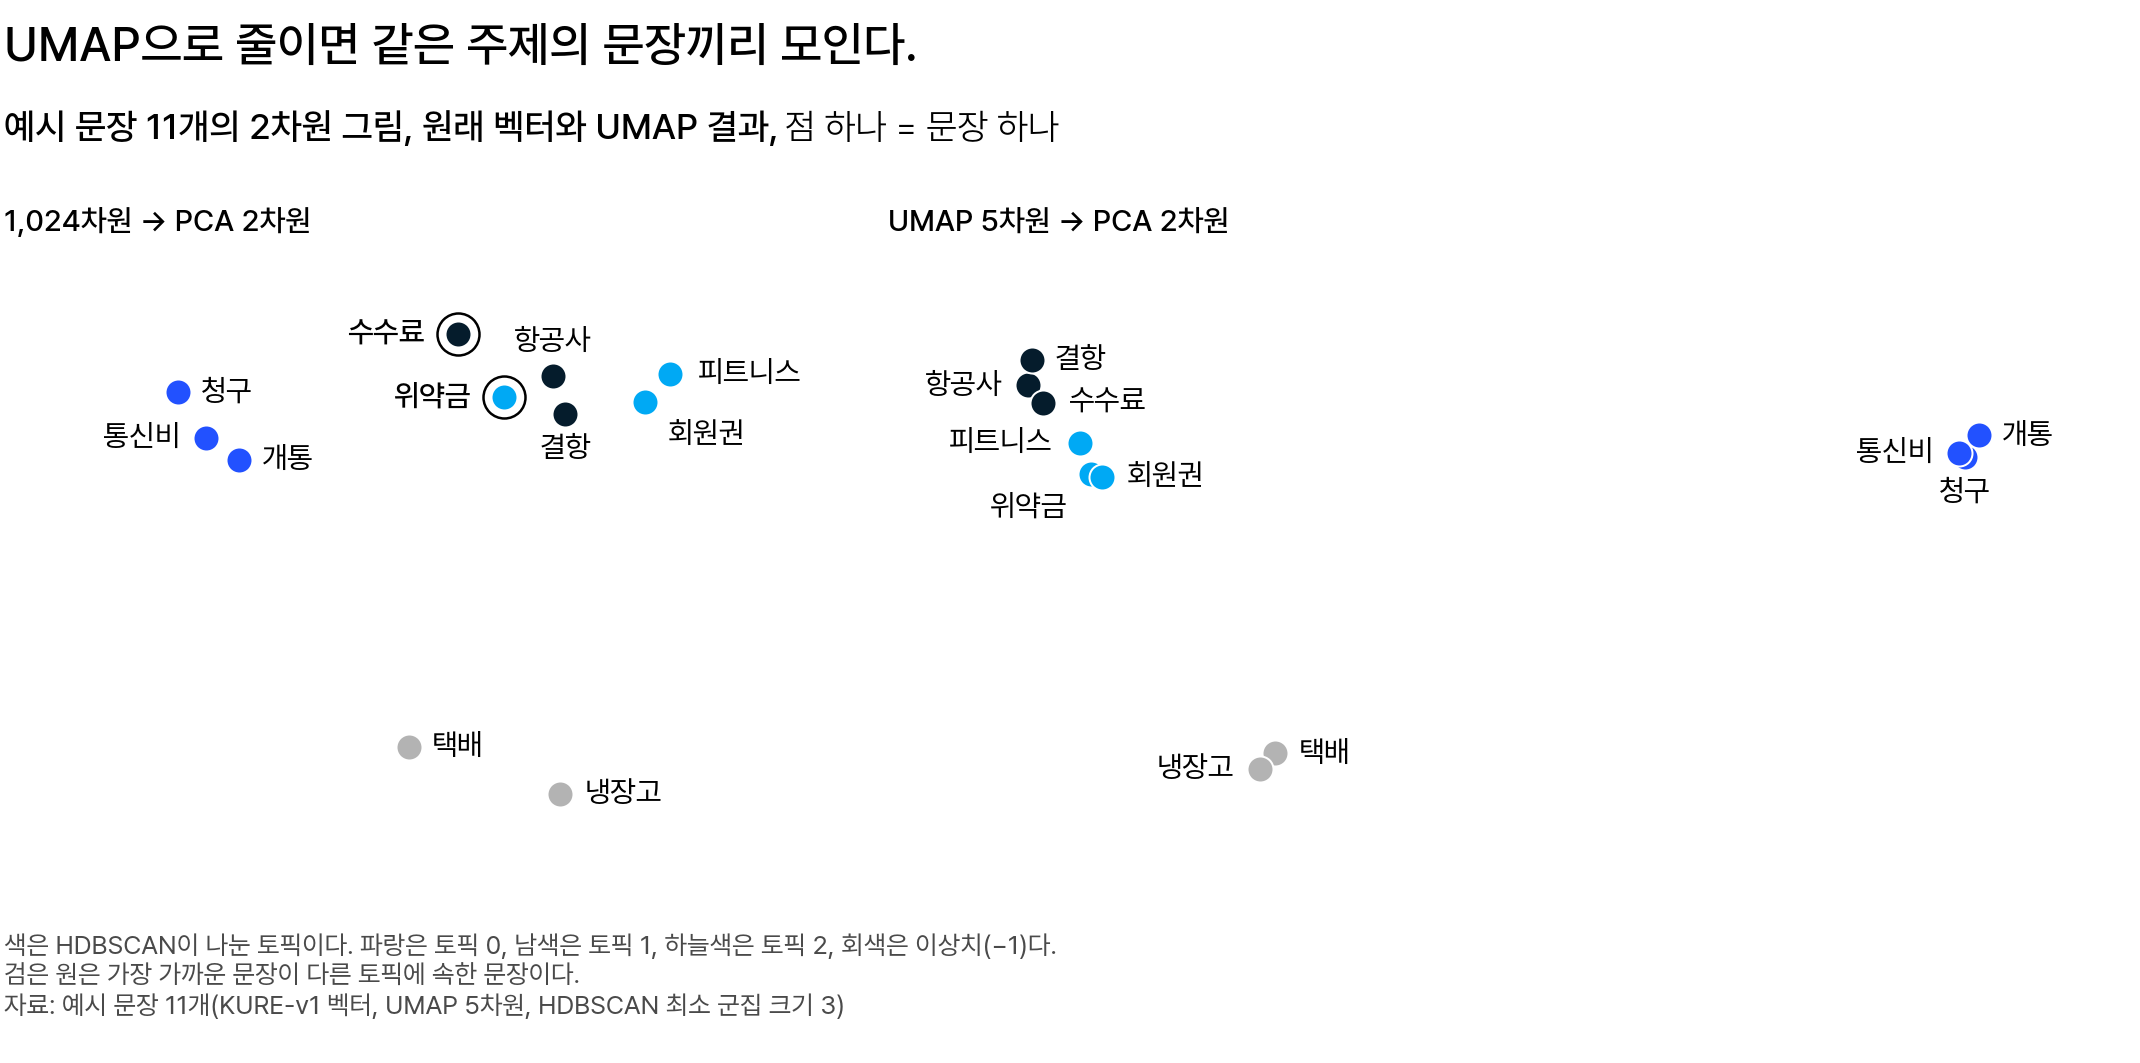

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로 · 세로는 PCA 로 줄인 두 축이라 값 자체에는 뜻이 없고, 점끼리 얼마나 가까운지만 본다. 왼쪽은 예시 문장의 1,024차원 벡터를 PCA 로 바로 2차원까지 줄인 그림이다. 오른쪽은 UMAP 이 만든 5차원 벡터를 같은 방법으로 줄인 그림이다. 점 하나가 문장 하나이고, 글자는 그 문장의 명사 하나다. 색은 HDBSCAN 이 나눈 토픽이고 회색은 이상치(−1)다. 검은 원은 가장 가까운 문장이 다른 토픽에 속한 문장이다</em></p>

왼쪽처럼 1,024차원을 PCA 로 바로 2차원까지 줄이면 항공권 환불 문장과 헬스장 해지 문장이 서로 가까이 있습니다. 주제가 있는 문장 9개 가운데 2개(검은 원)는 가장 가까운 문장이 다른 주제입니다. 「수수료」 문장은 「위약금」 문장과, 「위약금」 문장은 「항공사」 문장과 가장 가깝습니다.

오른쪽 UMAP 결과에서는 주제마다 3문장이 따로 모이고, 9개 모두 가장 가까운 문장이 같은 주제입니다. 밀도 기반 군집화는 가까운 이웃까지의 거리로 밀도를 계산합니다. 그래서 BERTopic 은 이웃 관계를 남기는 UMAP 으로 먼저 줄인 뒤 HDBSCAN 을 실행합니다.

<details class="lms-extra"><summary>자세히 — UMAP 이름의 뜻, PCA 와 비교, 인자, 민원 2만 건의 거리</summary>

**UMAP 이라는 이름의 뜻**

- U: Uniform(균일한)
- M: Manifold(매니폴드, 벡터들이 실제로 분포하는 더 낮은 차원의 곡면)
- A: Approximation(근사)
- P: Projection(투영)

벡터들이 매니폴드에 고르게 분포한다고 가정하고, 매니폴드를 이웃 그래프로 근사한 뒤 낮은 차원으로 옮긴다는 뜻입니다.

| | PCA | UMAP |
|---|---|---|
| 변환 방식 | 선형(가중치를 곱하고 더함) | 비선형(이웃 그래프를 만든 뒤 여러 번 고침) |
| 잘 보존하는 것 | 분산이 가장 큰 방향, 전체 구조 | 가까운 이웃 관계, 군집 구조 |
| 결과 해석 | 주성분이 원래 값의 가중합이라 비교적 쉬움 | 멀리 떨어진 두 점의 거리는 해석하기 어려움 |
| 결과 안정성 | 같은 자료면 같은 결과 | 인자와 시드에 따라 달라질 수 있음 |

UMAP 없이 1,024차원 벡터에 같은 설정의 HDBSCAN 을 실행하면, 헬스장 해지 문장 3개가 토픽 하나가 되지 못합니다. 1개는 항공권 환불 문장들과 같은 토픽에 속하고 2개는 이상치가 됩니다.

민원 2만 건과 예시 문장의 UMAP 인자는 이웃 수만 다릅니다.

| 인자 | 민원 2만 건 | 예시 문장 | 뜻 |
|---|---|---|---|
| `n_neighbors` | 15 | 3 | 문장마다 이웃 몇 개의 관계를 보존할지(자기 자신 포함) |
| `n_components` | 5 | 5 | 줄인 뒤의 차원 |
| `min_dist` | 0.0 | 0.0 | 줄인 공간에서 점끼리 얼마나 가까워도 되는지. 0 이면 이웃끼리 더 가깝게 모인다 |
| `metric` | "cosine" | "cosine" | 이웃을 찾을 때 쓰는 거리. 문장 임베딩을 배울 때의 코사인 |

아래 값은 문장(민원)마다 가장 가까운 거리를 가장 먼 거리로 나눈 값의 중앙값입니다. 예시 문장은 1,024차원에서 코사인 거리(1 − 코사인 유사도), 5차원에서 직선 거리로 구했습니다.

| 차원 | 예시 문장 11개 | 민원 2만 건 |
|---|---:|---:|
| 1,024 | 0.44 | 0.50 |
| 5 | 0.035 | 0.002 |

값이 0 에 가까울수록 가장 가까운 점과 가장 먼 점의 거리 차이가 커서, 밀도가 높은 영역을 찾기 쉽습니다.

**민원 2만 건의 2차원 그림에서 가까운 점은 같은 토픽인가요?**

민원 2만 건의 2차원 그림은 1,024차원 벡터를 UMAP 으로 2차원까지 따로 줄여 그린 것입니다. 토픽은 5차원 벡터로 정했으므로, 2차원 그림의 거리가 토픽과 꼭 맞지는 않습니다.

이 그림에서 토픽에 배정된 민원 13,390건마다 자기 자신을 뺀 가장 가까운 점 하나를 찾았습니다.

| 가장 가까운 점 | 건수 | 비율 |
|---|---:|---:|
| 같은 토픽 | 11,974 | 89.4% |
| 이상치 | 1,266 | 9.5% |
| 다른 토픽 | 150 | 1.1% |

토픽은 2차원 그림에서도 대체로 모여 보입니다. 어느 민원이 이상치인지는 민원마다 배정된 토픽 번호로 확인합니다.

</details>

### HDBSCAN 은 어떤 군집을 토픽으로 고르는가 [필수]

**HDBSCAN** 은 반경을 하나로 정하지 않는 밀도 기반 군집화 방법입니다. UMAP 이 만든 5차원 벡터에서 밀도가 높은 영역을 군집으로 고르고, 어느 군집에도 속하지 않은 점은 이상치(−1)가 됩니다.

- H: Hierarchical(계층)
- DB: Density-Based(밀도 기반)
- SCAN: Spatial Clustering of Applications with Noise(잡음이 있는 공간 군집)

HDBSCAN 은 거리 기준을 크게 정했다가 조금씩 좁혀 가며, 점들이 어떤 군집으로 나뉘는지 기록합니다. **계층 트리** 는 이렇게 군집이 나뉘는 차례를 기록한 트리이고, 이름의 H(계층)가 여기서 왔습니다. 예시 문장 11개는 다음 차례로 나뉩니다(수는 밀도를 반영한 거리).

```text
문장 11개 전체
  10.62 에서 둘로 나뉨
  ├ 휴대폰 요금 3문장
  └ 나머지 8문장
      4.87 에서 냉장고, 4.76 에서 택배가 한 문장씩 떨어져 나감
      1.45 에서 둘로 나뉨
      ├ 항공권 환불 3문장
      └ 헬스장 해지 3문장
```

최소 군집 크기보다 작게 떨어져 나간 점은 군집이 되지 못합니다. **안정성** 은 거리 기준을 바꿔도 군집이 계속 유지되는 정도이고, HDBSCAN 은 남은 군집 가운데 안정성이 큰 군집을 토픽으로 고릅니다. 거리를 계산하고 안정성을 비교하는 차례는 「자세히」 상자에서 따라갑니다.

**분석가는 무엇을 정하나요?**

분석가가 주로 정하는 값은 **최소 군집 크기**(min_cluster_size)입니다. 군집으로 인정할 최소 점 수이고, 토픽 수는 HDBSCAN 이 끝나야 정해집니다. min_samples 는 밀도를 계산할 때 몇 번째로 가까운 이웃까지의 거리를 쓸지 정하는 값입니다. 따로 정하지 않으면 최소 군집 크기와 같습니다.

예시 문장은 최소 군집 크기 3, min_samples 2 로 계산해 토픽 3개와 이상치 2개가 됩니다. min_samples 를 기본값 3 으로 두면 문장이 적어 11개 모두 이상치가 됩니다. 택배 · 냉장고 문장은 서로 가장 가깝지만, 두 문장만으로는 최소 군집 크기를 채우지 못해 이상치가 됩니다.

민원 2만 건은 최소 군집 크기 100 에서 토픽 40개가 되었고, 민원 3건 가운데 1건이 이상치입니다.

반경은 정하지 않습니다. UMAP 이 만든 벡터는 거리에 정해진 단위가 없어 알맞은 반경을 미리 알 수 없기 때문입니다. 필수 머신러닝의 DBSCAN 은 반경 하나(`eps`)를 정했습니다. scikit-learn 예제의 점 750개에서 점 사이 거리만 바꿔, 두 방법이 고르는 군집을 비교합니다.

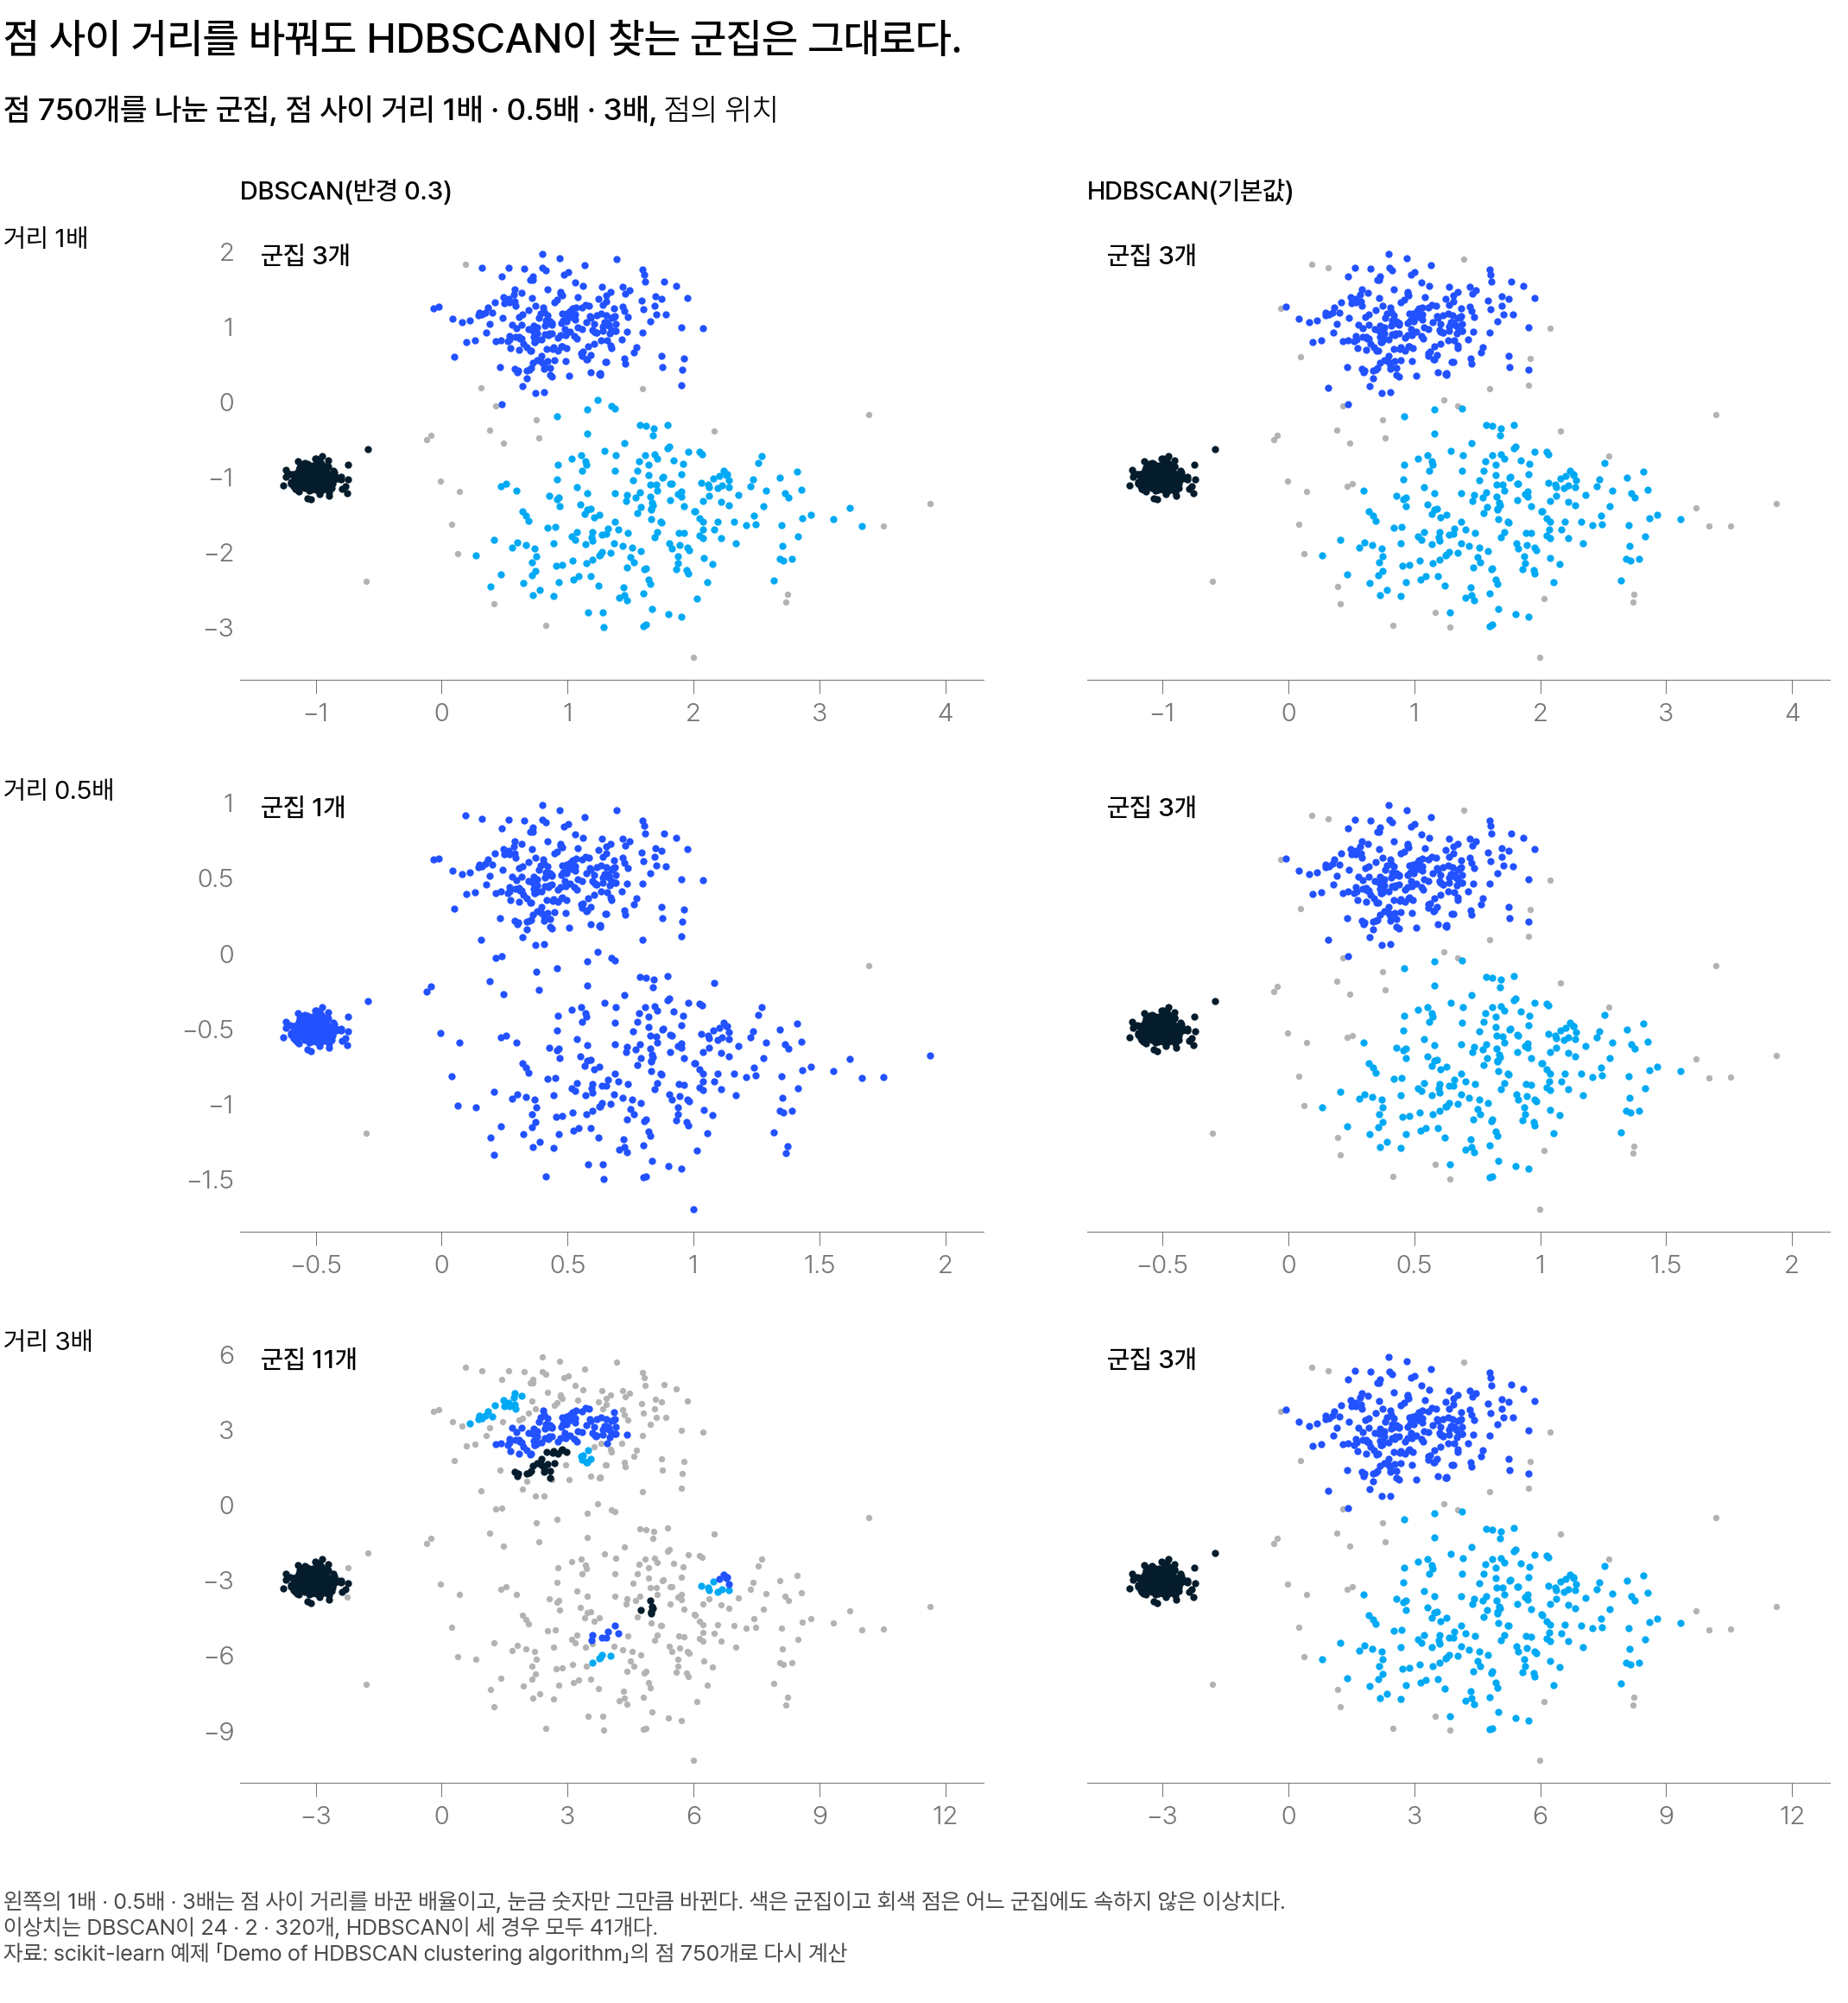

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 왼쪽 세 그림은 DBSCAN(반경 0.3), 오른쪽 세 그림은 HDBSCAN(기본값)이고 위에서부터 점 사이 거리 1배 · 0.5배 · 3배다. 가로 · 세로는 점의 위치이고, 색은 군집, 회색 점은 이상치다</em></p>

DBSCAN 은 반경 0.3 이 그대로라, 점 사이가 좁아지면 군집이 하나로 합쳐지고 넓어지면 잘게 나뉩니다. HDBSCAN 은 거리 기준을 하나로 정하지 않고, 가장 긴 연결부터 끊어 가며 모든 거리 기준에서 군집이 나뉘는 차례를 기록합니다. 거리를 같은 배율로 바꿔도 이 차례는 같아서 같은 군집을 고릅니다. 그래서 임베딩처럼 거리에 단위가 없는 자료에는 HDBSCAN 을 씁니다.

<details class="lms-extra"><summary>더 깊이 — scikit-learn 예제의 원래 그림</summary>

위 그림은 scikit-learn 예제의 두 그림을 한 장으로 다시 그린 것입니다. 예제는 DBSCAN 과 HDBSCAN 을 따로 그렸습니다.

<img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_hdbscan_002.png" alt="DBSCAN eps 0.3 으로 같은 점을 1배·0.5배·3배로 바꿨을 때의 군집 세 그림" width="500" height="600" />
<p align="center"><em>▲ 가로 · 세로는 점의 위치다. DBSCAN(eps=0.3)으로 같은 점을 위에서부터 1배 · 0.5배 · 3배로 바꿔 나눈 그림이다. 거리 배율에 따라 군집 수가 바뀐다 (출처: scikit-learn 예제 「Demo of HDBSCAN clustering algorithm」, BSD-3-Clause)</em></p>

<img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_hdbscan_004.png" alt="HDBSCAN 기본값으로 같은 점을 1배·0.5배·3배로 바꿨을 때의 군집 세 그림" width="500" height="600" />
<p align="center"><em>▲ 같은 점을 HDBSCAN 기본값으로 나눈 그림이다. 세 그림 모두 군집 수가 같아 같은 그림처럼 보이고 눈금 숫자만 다르다 (출처: scikit-learn 예제 「Demo of HDBSCAN clustering algorithm」, BSD-3-Clause)</em></p>

두 그림에서 × 기호는 이상치입니다.

</details>

<details class="lms-extra"><summary>자세히 — HDBSCAN 이 계층 트리로 군집을 고르는 과정</summary>

예시 문장 11개의 5차원 벡터를 최소 군집 크기 3, min_samples 2 로 계산했습니다. 주제마다 문장이 3개뿐이라 min_samples 를 기본값 3 보다 작게 정했습니다(3 이면 11개 모두 이상치가 됩니다).

```text
문장마다 5차원 벡터
   ↓ ① 핵심 거리 · ② 상호 도달 가능 거리
밀도를 반영한 거리
   ↓ ③ 최소 신장 트리
모든 문장을 가장 짧게 잇는 연결 10개
   ↓ ④ 가장 긴 연결부터 끊기
계층 트리
   ↓ ⑤ 최소 군집 크기보다 작게 나뉜 쪽 정리
응축 트리
   ↓ ⑥ 안정성이 큰 군집 선택
⑦ 토픽 0 · 1 · 2 와 이상치(−1)
```

**① 핵심 거리(core distance)**

점마다 min_samples 번째로 가까운 점까지의 거리입니다. 밀집 지역의 점은 가까운 이웃이 많아 작고, 희소 지역의 점은 큽니다. min_samples 2 이면 두 번째로 가까운 문장까지의 거리입니다.

| 문장 | 핵심 거리 |
|---|---:|
| 휴대폰 요금 3문장 | 0.46～0.52 |
| 항공권 환불 3문장 | 0.51～0.64 |
| 헬스장 해지 3문장 | 0.58～0.76 |
| 택배 | 4.76 |
| 냉장고 | 4.87 |

택배와 냉장고는 서로 0.35 로 가장 가깝습니다. 하지만 두 번째로 가까운 문장이 둘 다 멀리 있는 헬스장 회원권 문장이라 핵심 거리가 큽니다.

**② 상호 도달 가능 거리(mutual reachability distance)**

두 점의 실제 거리와 두 점 각각의 핵심 거리, 이 셋 가운데 가장 큰 값입니다. 예를 들어 a 의 핵심 거리가 2, b 의 핵심 거리가 5, 실제 거리가 3 이면 상호 도달 가능 거리는 5 입니다.

희소 지역의 점은 실제로 가까워도 다른 점과 멀어집니다. 그래서 우연히 가까운 잡음 점이 군집에 묶이는 일이 줄어듭니다. 택배와 냉장고도 실제 거리는 0.35 이지만 상호 도달 가능 거리는 4.87 입니다.

**③ 최소 신장 트리(minimum spanning tree)**

모든 점을 이으면서 연결 길이(상호 도달 가능 거리)의 합이 가장 작은 트리입니다. 점이 n개면 연결은 n − 1개라, 예시 문장 11개는 연결 10개입니다.

| 연결 | 상호 도달 가능 거리 |
|---|---:|
| 휴대폰 요금 문장끼리 2개 | 0.52 |
| 항공권 환불 문장끼리 2개 | 0.64 |
| 헬스장 해지 문장끼리 2개 | 0.76 |
| 항공권 취소 수수료와 헬스장 중도 해지 | 1.45 |
| 택배와 헬스장 회원권 환불 | 4.76 |
| 냉장고와 택배 | 4.87 |
| 이번 달 통신비와 택배 | 10.62 |

**④ 가장 긴 연결부터 끊기**

가장 긴 연결부터 하나씩 끊으면 위 본문의 계층 트리가 나옵니다. 트리의 위가 문장 11개 전체이고, 아래로 내려갈수록 짧은 연결이 끊깁니다.

| 끊는 연결 | 상호 도달 가능 거리 | 나뉜 결과 |
|---|---:|---|
| 이번 달 통신비와 택배 | 10.62 | 휴대폰 요금 3문장 / 나머지 8문장 |
| 냉장고와 택배 | 4.87 | 7문장 / 냉장고 |
| 택배와 헬스장 회원권 환불 | 4.76 | 항공권 · 헬스장 6문장 / 택배 |
| 항공권 취소 수수료와 헬스장 중도 해지 | 1.45 | 항공권 환불 3문장 / 헬스장 해지 3문장 |
| 주제 안의 연결 6개 | 0.76 · 0.64 · 0.52 | 주제마다 3문장이 한꺼번에 떨어져 나감 |

주제 안의 연결 2개는 상호 도달 가능 거리가 같습니다. 3문장 가운데 가장 큰 핵심 거리가 두 연결의 상호 도달 가능 거리가 되기 때문입니다. 그래서 두 연결이 같은 거리에서 함께 끊기고, 세 문장이 한꺼번에 떨어져 나갑니다.

**⑤ 작게 나뉜 쪽 정리**

**응축 트리(condensed tree)** 는 계층 트리에서 최소 군집 크기보다 작게 나뉜 쪽을 군집으로 인정하지 않는 트리입니다. 그쪽의 점은 부모 군집에서 떨어져 나간 점이 됩니다. 최소 군집 크기 3 으로 ④ 의 표를 정리하면 이렇습니다.

- 10.62 에서는 두 쪽 모두 3문장 이상이라, 휴대폰 요금 군집과 8문장 군집(항공권 · 헬스장 · 택배 · 냉장고)으로 나뉩니다.
- 4.87 과 4.76 에서는 냉장고와 택배가 한 문장씩 나뉩니다. 둘은 군집이 아니라 8문장 군집에서 떨어져 나간 점입니다.
- 1.45 에서는 두 쪽 모두 3문장이라, 8문장 군집이 항공권 환불 군집과 헬스장 해지 군집으로 나뉩니다.
- 그 아래에서는 3문장이 한꺼번에 떨어져 나가므로 새 군집이 생기지 않습니다.

**⑥ 안정성으로 군집 고르기**

한 군집이 여러 거리 기준에서 계속 비슷한 크기로 유지되면 안정적이고, 좁은 범위에서만 나타나면 불안정합니다. 계산에는 거리 대신 λ = 1 ÷ 거리를 씁니다. 트리의 아래로 내려갈수록 거리는 짧아지고 λ 는 커집니다. λ 는 거리가 짧을수록 커지므로 밀도와 같은 방향의 값입니다.

**안정성(stability)** 은 군집의 점마다 「그 점이 떨어져 나갈 때의 λ − 그 군집이 생길 때의 λ」를 구해 더한 값입니다. 군집이 두 군집으로 나뉠 때는, 남아 있던 점이 모두 그때의 λ 에서 떨어져 나간 것으로 계산합니다. 점마다 구한 λ 차이는 그 점이 군집 안에 머문 구간의 길이입니다. λ 는 반올림하기 전 거리로 구했습니다.

| 군집 | 생길 때 λ | 떨어져 나갈 때 λ | 안정성 |
|---|---:|---|---:|
| 휴대폰 요금 | 0.094 | 3문장 모두 1.910 | 3 × (1.910 − 0.094) = 5.45 |
| 8문장 군집 | 0.094 | 냉장고 0.205, 택배 0.210, 나머지 6문장 0.691 | (0.205 − 0.094) + (0.210 − 0.094) + 6 × (0.691 − 0.094) = 3.81 |
| 항공권 환불 | 0.691 | 3문장 모두 1.554 | 3 × (1.554 − 0.691) = 2.59 |
| 헬스장 해지 | 0.691 | 3문장 모두 1.312 | 3 × (1.312 − 0.691) = 1.86 |

한 군집과 그 안에서 나뉜 군집은 함께 고르지 않습니다. 8문장 군집의 안정성은 3.81 이고, 그 안의 두 군집은 합해 2.59 + 1.86 = 4.45 입니다. 합이 더 크므로 항공권 환불 군집과 헬스장 해지 군집을 고릅니다.

휴대폰 요금 군집은 안에서 나뉜 군집이 없어 그대로 고릅니다. hdbscan 라이브러리는 기본으로 문장 11개 전체를 군집 하나로 고르지 않습니다. 전체를 하나로 고르면 나눈 결과가 없기 때문입니다.

**⑦ 결과**

고른 세 군집이 토픽 0 · 1 · 2(휴대폰 요금 · 항공권 환불 · 헬스장 해지)가 됩니다. 택배 · 냉장고는 고르지 않은 8문장 군집에서 떨어져 나간 점이라 이상치(−1)가 됩니다.

hdbscan 문서의 원래 그림도 위에서 아래로 나뉘는 응축 트리입니다. 세로축은 λ 이고, 아래로 갈수록 커집니다(거리가 짧아집니다).

<img src="https://hdbscan.readthedocs.io/en/latest/_images/how_hdbscan_works_18_1.png" alt="세로축이 λ 값인 응축 트리. 고른 가지 3개에 파랑 · 초록 · 빨강 타원이 그려져 있다" width="560" height="380"/>
<p align="center"><em>▲ hdbscan 문서의 원래 그림이다. 최소 군집 크기 5 로 만든 응축 트리이고, 타원을 친 가지 3개가 고른 군집이다 (출처: hdbscan 문서 「How HDBSCAN Works」, Leland McInnes 외, BSD-3-Clause)</em></p>

</details>

### c-TF-IDF 는 상위 단어를 어떻게 고르는가 [필수]

토픽 번호만으로는 그 토픽이 무슨 주제인지 알 수 없어, 토픽을 잘 나타내는 단어가 필요합니다. **c-TF-IDF**(class-based TF-IDF)는 한 단어가 그 토픽을 얼마나 잘 나타내는지 매기는 점수입니다. 그 토픽에 자주 나오고 다른 토픽에는 드문 단어일수록 큽니다.

**토픽 문서는 어떻게 만드나요?**

토픽마다 속한 문장의 명사를 모두 합쳐 토픽 문서 하나로 만듭니다. 이상치 문장도 토픽 문서 하나로 모으므로, 예시 문장의 토픽 문서는 4개입니다. 토픽 1 의 토픽 문서는 명사 9개입니다.

```text
항공사가 항공권 환불을 미루고 있어요 → 항공사 · 항공 · 환불
항공권 취소 수수료를 과하게 뗐습니다 → 항공 · 취소 · 수수료
결항된 항공편 환불을 받지 못했어요 → 결항 · 항공편 · 환불
토픽 문서 「토픽 1」 → 항공사 · 항공 · 환불 · 항공 · 취소 · 수수료 · 결항 · 항공편 · 환불
```

명사는 Kiwi 로 형태소 분석해 얻었습니다. 「항공권」은 명사 「항공」과 접미사로 나뉘어 「항공」만 남습니다.

**점수는 어떻게 계산하나요?**

점수는 토픽 안 비율 tf 와 로그 항의 곱입니다.

$$
W_{t,k} = \mathrm{tf}_{t,k} \times \log\left(1 + \frac{A}{f_t}\right)
$$

- $W_{t,k}$: 토픽 $k$ 에서 단어 $t$ 의 c-TF-IDF 점수
- $\mathrm{tf}_{t,k}$: 토픽 $k$ 의 토픽 문서에서 단어 $t$ 가 나온 횟수 ÷ 그 토픽 문서의 명사 수
- $f_t$: 모든 토픽 문서에서 단어 $t$ 가 나온 횟수의 합(전체 횟수)
- $A$: 토픽 문서 하나의 평균 명사 수(소수점 아래 버림)
- $\log$: 자연로그

다른 토픽에 드문 단어는 $f_t$ 가 작아 로그 항이 커집니다. 예시 문장은 토픽 문서 4개의 명사가 모두 36개라 $A = 9$ 입니다.

| 토픽 1 의 단어 | 토픽 1 안 횟수 | tf | 전체 횟수 $f_t$ | 로그 항 | 점수 $W$ |
|---|---:|---:|---:|---:|---:|
| 항공 | 2 | 0.2222 | 2 | 1.7047 | **0.3788** |
| 환불 | 2 | 0.2222 | 4 | 1.1787 | **0.2619** |

두 단어는 토픽 1 에 2번씩 나와 tf 가 같습니다. 그런데 「환불」은 헬스장 해지 토픽에도 나와 전체 횟수가 커서, 로그 항과 점수가 작습니다.

**이름의 c 와 로그 안의 1 은 왜 있나요?**

- c 는 class(집단)의 머리글자입니다. 문장 하나가 아니라 토픽 하나를 문서 하나로 보고 점수를 매긴다는 뜻입니다.
- 로그 안에 1 을 더하므로 로그 항이 늘 0 보다 커서 점수가 음수가 되지 않습니다.

집단 특징 단어를 찾을 때 본 TF-IDF 도 집단마다 문서 하나로 합쳤으므로 생각은 같습니다. 다른 점은 흔한 정도를 단어가 나온 문서 수 대신 전체 횟수 $f_t$ 로 계산한다는 것입니다.

<details class="lms-extra"><summary>더 깊이 — TF-IDF 와 c-TF-IDF 의 가중치 비교</summary>

| | TF-IDF(집단 특징 단어) | c-TF-IDF |
|---|---|---|
| 문서 하나 | 집단 하나의 리뷰를 모두 합쳐 만든 문서 | 토픽 하나의 명사를 모두 합쳐 만든 토픽 문서 |
| 문서 수 | 2개 | 민원은 41개(토픽 40개와 이상치) |
| 흔한 정도 | 단어가 나온 문서 수 df | 단어가 나온 전체 횟수 $f_t$ |
| 단어마다 곱하는 가중치 | 1 과 1.405 두 값뿐 | 단어마다 다름 |

집단 특징 단어를 찾을 때 쓴 가중치는 $\ln((1 + N)/(1 + \mathrm{df})) + 1$ 이고, $N$ 은 문서 수, df 는 단어가 나온 문서 수입니다. 문서가 2개이면 df 는 1 이나 2 뿐입니다.

- 두 문서에 모두 나온 단어: $\ln \frac{3}{3} + 1 = 1$
- 한 문서에만 나온 단어: $\ln \frac{3}{2} + 1 = 1.405$

그래서 TF-IDF 는 가중치가 두 값뿐이라 흔한 단어가 상위를 차지했습니다. c-TF-IDF 는 전체 횟수 $f_t$ 가 단어마다 달라 로그 항도 단어마다 다릅니다.

</details>

**민원 2만 건에서는 어떤 단어가 1위인가요?**

민원은 토픽 40개와 이상치로 토픽 문서가 41개이고, $A$ 는 2,350 입니다. 민원 토픽 0 에서는 「해지」가 가장 많이 나왔지만 점수 1위는 「개통」입니다. 「해지」는 다른 토픽에도 흔해 로그 항이 작습니다. 예시 문장의 「환불」도 항공권 환불과 헬스장 해지 두 토픽에 나와 로그 항이 작았습니다.

| 단어 | 토픽 0 안 횟수 | tf | 전체 횟수 $f_t$ | 로그 항 | 점수 $W$ |
|---|---:|---:|---:|---:|---:|
| 개통 | 266 | 0.0330 | 271 | 2.2692 | **0.0749** |
| 해지 | 378 | 0.0469 | 2,176 | 0.7324 | **0.0343** |

토픽 0 의 상위 단어 10개에서도 횟수 순위와 점수 순위가 다른지 아래 그림으로 확인합니다.

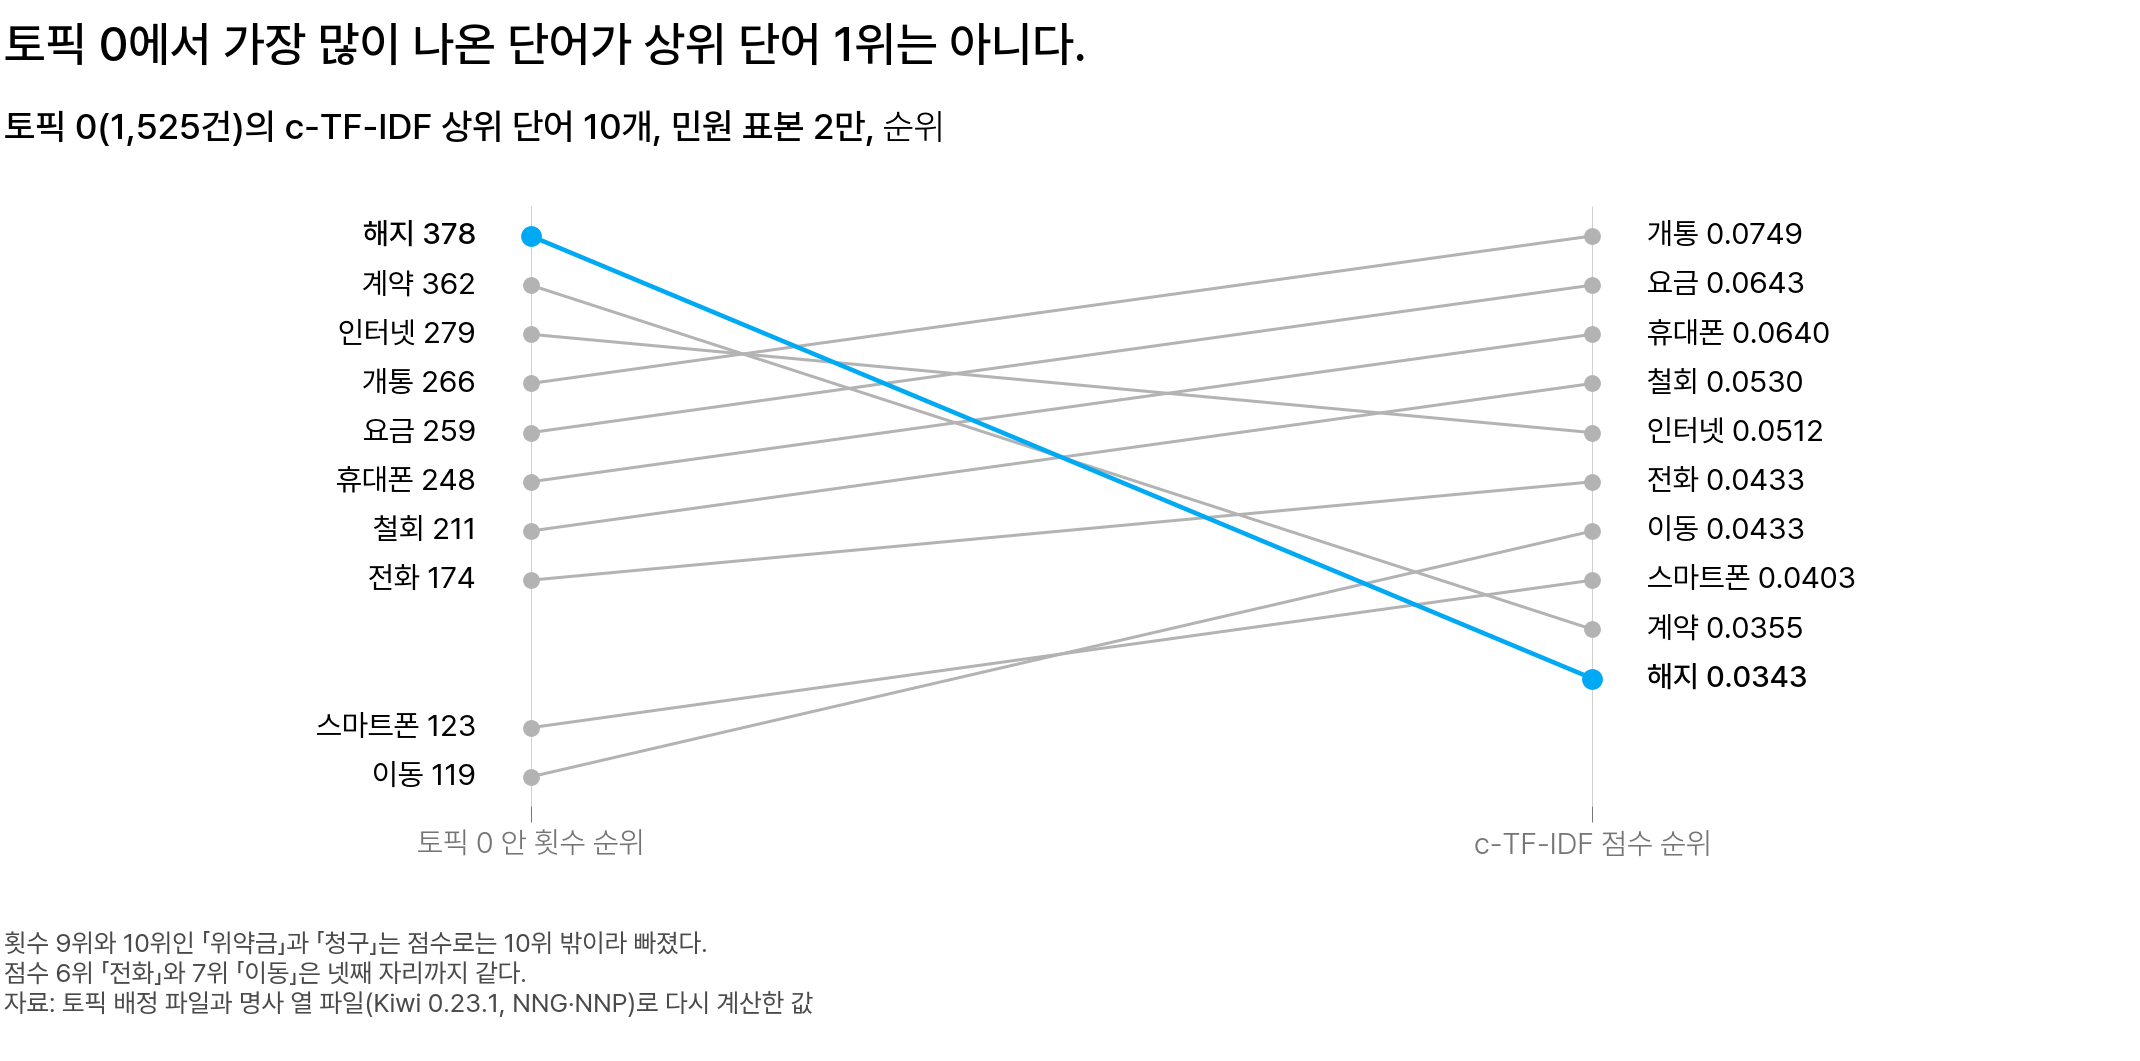

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축의 두 위치는 토픽 0 안 횟수 순위와 c-TF-IDF 점수 순위이고, 세로는 순위(위가 1위)다. 선 하나가 단어 하나이고, 하늘색 선 「해지」는 횟수로 1위, 점수로 10위다. 회색 선은 나머지 단어 9개다</em></p>

아래 셀은 상위 단어 10개의 점수를 식대로 다시 계산하고 두 순위를 함께 출력합니다.

In [ ]:
# 토픽 0 의 상위 단어 10개: c-TF-IDF 점수 W = tf × log(1 + A / f_t) 를 식대로 계산해 두 순위를 비교한다
import numpy as np
import pandas as pd

N_T0, A = 8063, 2350        # 토픽 0 문서의 명사 수, 문서 하나의 평균 명사 수
counts = {                  # 단어: (토픽 0 안 횟수, 41개 문서 전체 횟수 f_t)
    "해지": (378, 2176), "계약": (362, 1954), "인터넷": (279, 692), "개통": (266, 271),
    "요금": (259, 367), "휴대폰": (248, 335), "철회": (211, 358), "전화": (174, 365),
    "스마트폰": (123, 180), "이동": (119, 132)}
df = pd.DataFrame(counts, index=["토픽 안 횟수", "전체 횟수"]).T
df["tf"] = df["토픽 안 횟수"] / N_T0
df["로그 항"] = np.log(1 + A / df["전체 횟수"])
df["W"] = df["tf"] * df["로그 항"]
df["횟수 순위(10개 안)"] = df["토픽 안 횟수"].rank(ascending=False).astype(int)   # 이 10개 안에서 매긴 순위
df["점수 순위"] = df["W"].rank(ascending=False).astype(int)
table = df.sort_values("점수 순위").round(4)
DIGITS = {"tf": 4, "로그 항": 4, "W": 4}                                   # 소수 넷째 자리까지 출력(마지막 0 도 표시)
table = table.apply(lambda col: col.map(("{:.%df}" % DIGITS[col.name]).format) if col.name in DIGITS else col)
for name, *vals in table.itertuples():
    print(f"{name}: " + " · ".join(f"{k} {v}" for k, v in zip(table.columns, vals)))

출력에서도 횟수 순위와 점수 순위가 크게 다릅니다.

```text
「해지」 횟수 1위 → 점수 10위
「계약」 횟수 2위 → 점수 9위
「개통」 횟수 4위 → 점수 1위
```

출력의 횟수 순위는 이 10개 단어 안에서 매긴 순위입니다.

**상위 단어가 이상하면 어디를 고치나요?**

상위 단어가 이상하게 나오면 c-TF-IDF 단계만 고치면 됩니다. c-TF-IDF 는 토픽 배정이 끝난 뒤에 계산하기 때문입니다. 실제로 불용어 9개를 빼기 전과 뺀 뒤의 배정은 2만 건 모두 같았고 상위 단어만 바뀌었습니다.

- 주제와 상관없는 말이 보이면 불용어 목록을 고칩니다.
- 잘못 잘린 명사가 보이면 형태소 분석을 고칩니다.
- 상위 단어가 비거나 LG · SK 같은 영문 약자만 보이면 BERTopic 을 만들 때의 `language` 인자를 확인합니다. 기본값 `"english"` 이면 c-TF-IDF 전에 영문자 · 숫자가 아닌 글자가 지워집니다.

어느 경우든 토픽 번호는 다시 만들지 않으므로 토픽 수와 비율도 그대로입니다.

**다시 적합해도 같은 토픽이 나오나요?**

UMAP 은 시드를 고정해도 이웃을 빠르게 찾는 근사 계산과 기기 차이 때문에 실행마다 결과가 조금 다릅니다. 그래서 다시 적합하면 토픽 번호와 수가 바뀔 수 있습니다. 이 수업의 건수와 비율은 모두 토픽 배정 파일 하나로 계산합니다. 토픽 배정 파일은 최소 군집 크기 100 · 시드 0 으로 한 번 적합해 민원마다 토픽 번호를 기록한 파일입니다.

<details class="lms-extra"><summary>더 깊이 — 시드를 고정해도 토픽 표가 달라지는 이유</summary>

UMAP 의 무작위성은 `random_state` 로 시드를 정해 고정합니다. 그래도 토픽 표가 달라지는 이유를 민원 2만 건에서 확인했습니다.

- UMAP 은 이웃을 찾을 때 기본으로 근사 계산을 씁니다. 모든 거리를 계산하지 않고 빠르게 찾는 방식인데, 같은 `random_state` 로 두 번 실행해도 줄인 벡터가 달라졌습니다. 이웃을 정확히 계산해 전달하면 두 번의 결과 차이가 0.0 이었으므로 차이는 이웃 검색에서 생깁니다.
- 같은 KURE-v1 이라도 CPU 와 MPS(맥의 GPU)에서 계산한 벡터는 최대 6.8×10⁻⁷ 다릅니다. 이 작은 차이로도 군집 경계에 있던 민원은 다른 토픽에 배정될 수 있습니다.

토픽 배정 파일은 이웃을 정확히 계산해 UMAP 에 전달해 만들었습니다. 다른 기기에서 계산한 벡터로 다시 적합해 토픽 배정 파일과 비교했습니다.

| 비교한 값 | 토픽 배정 파일 | 다시 적합한 결과 |
|---|---:|---:|
| 토픽 수 | 40개 | 41개 |
| 이상치 비율 | 33.05% | 32.2% |

토픽 수와 이상치 비율은 조금만 달라졌습니다. 반면 토픽 번호가 토픽 배정 파일과 같은 민원은 45.6% 뿐입니다.

45.6% 는 번호끼리만 비교한 비율입니다. 토픽 번호는 크기 순서로 다시 매기므로, 같은 토픽도 번호가 바뀌면 이 비율에서는 다른 토픽으로 집계됩니다. 그래서 다시 적합한 표는 번호가 아니라 토픽 수와 이상치 비율로 비교합니다.

</details>

> **[문제] c-TF-IDF 는 토픽 하나의 민원을 모두 합쳐 토픽 문서 하나로 보고 단어 점수를 매긴다. 집단 특징 단어를 찾을 때 별점 1·2점 리뷰 전체를 한 문서로 보고 TF-IDF 를 계산한 것과 같은 발상이다.**
>
> 1. O (맞다)
> 2. X (틀리다)

<details class="lms-extra"><summary>자세히 — 「개통」의 c-TF-IDF 점수 계산</summary>

토픽 0 의 토픽 문서에는 명사 8,063개가 있습니다. 토픽 0 민원 1,525건의 명사를 모은 뒤, 아래 두 가지를 거치고 남은 수입니다.

- 토픽 문서 41개 가운데 두 곳 이상에 나온 명사만 남깁니다(`min_df=2`).
- 불용어 9개를 뺍니다.

불용어는 분석에서 빼는 흔한 말입니다. 이 9개는 문의 · 요청 · 관련 · 요구 · 건 · 후 · 상담 · 불만 · 피해이고 문서 비율을 배울 때 쓴 목록과 같습니다. 불용어까지 빼고 남은 명사는 3,080종입니다.

이제 식에 $t$ = 개통, $k = 0$ 을 대입합니다. 「개통」은 토픽 0 안에서 266번, 토픽 문서 41개 전체에서 271번 나왔습니다.

| 차례 | 계산 | 값 |
|---|---|---:|
| ① 평균 명사 수 | 토픽 문서 41개의 명사 수 합 96,389 ÷ 41 | 2,350.95 |
| ② $A$ | ① 에서 소수점 아래를 버림 | 2,350 |
| ③ $\mathrm{tf}_{t,0}$ | 266 ÷ 8,063 | 0.0330 |
| ④ $A \div f_t$ | 2,350 ÷ 271 | 8.672 |
| ⑤ 로그 항 | ln(1 + 8.672) = ln 9.672 | 2.2692 |
| ⑥ $W_{t,0}$ | ③ × ⑤ = 0.0330 × 2.2692 | 0.0749 |

③ 은 토픽 0 의 명사 가운데 「개통」이 차지하는 비율입니다. ④ 는 평균 명사 수가 「개통」 전체 횟수의 몇 배인지이고, 드문 단어일수록 이 배수가 큽니다. ⑤ 는 그 배수에 1 을 더해 자연로그를 구한 값입니다.

③ 과 ⑤ 를 곱한 0.0749 가 토픽 0 의 1위 점수입니다.

</details>

> **[문제] 「계약」의 c-TF-IDF 점수 손계산**
>
> 토픽 0 의 명사를 토픽 문서 하나로 모으면 8,063개이고 A = 2,350 입니다. 「계약」은 토픽 0 안에서 362번, 토픽 문서 41개 전체에서 1,954번 나왔습니다. c-TF-IDF 점수를 구하고 토픽 0 안에서 둘째로 많이 나왔는데도 점수가 작은 이유를 한 문장으로 적어 보세요.

<div class="lms-summary">

**정리**

BERTopic 은 문장 임베딩 → UMAP → HDBSCAN → c-TF-IDF 를 차례로 실행합니다. 앞 단계의 출력이 다음 단계의 입력이 됩니다.

- UMAP 은 가까운 이웃이 가까이 남도록 1,024차원 벡터를 5차원 벡터로 줄입니다.
- HDBSCAN 은 여러 거리 기준에서 계속 유지되는 군집을 토픽으로 고르고, 어느 토픽에도 속하지 않은 민원은 이상치(−1)가 됩니다.
- c-TF-IDF 는 배정이 끝난 뒤, 그 토픽에 자주 나오고 다른 토픽에 드문 단어를 상위 단어로 고릅니다.

**할 일**

- 토픽 배정 파일(민원마다 토픽 번호)을 저장하고, 인코더 · 이웃 수 · 시드 · 최소 군집 크기 · 불용어 목록을 함께 기록합니다
- 상위 단어가 이상하면 토픽 번호는 두고 불용어 목록 · 형태소 분석 · `language` 인자를 확인합니다

이 수업의 건수와 비율은 모두 한 번 적합한 토픽 배정 파일로 계산합니다.

</div>

> **[문제] 실습 준비 셀이 BERTopic(language="multilingual", …) 을 씁니다. 이 인자를 빼서 기본값 language="english" 로 두고 한글 명사 문서를 전달하면 어떻게 될까요?**
>
> 1. 영어 불용어만 추가로 빠지고 결과는 같다
> 2. c-TF-IDF 앞 전처리가 영문자·숫자가 아닌 글자를 지워 한글 상위 단어가 사라진다
> 3. 임베딩 모델이 영어 모델로 바뀌어 토픽 수가 줄어든다
> 4. 오류가 나서 실행이 멈추므로 바로 알아챈다

## 3. 토픽 수는 어떻게 정하는가

토픽 표의 토픽 40개는 어떻게 정해진 수일까요?

토픽 수는 분석가가 직접 정하지 않습니다. 분석가가 최소 군집 크기를 고르면, 그 값에서 HDBSCAN 이 찾은 군집 수가 토픽 수가 됩니다.

최소 군집 크기는 시드를 바꿔도 토픽 수가 같은지와 이상치 비율을 보고 고릅니다. 민원 토픽 표는 최소 군집 크기 100 에서 토픽 40개가 나왔습니다.

### 최소 군집 크기를 키우면 토픽 수는 어떻게 되는가 [필수]

최소 군집 크기보다 민원이 적은 군집은 토픽이 되지 못하고, 이웃 군집과 합쳐지거나 이상치가 됩니다. 예를 들어 민원이 120건씩인 군집 2개가 서로 이웃해 있습니다.

| 최소 군집 크기 | 120건 군집 2개의 결과 | 토픽 수 |
|---|---|---:|
| 100 | 둘 다 100건을 넘어 따로 토픽이 된다 | 2 |
| 150 | 둘 다 150건에 못 미쳐, 합친 240건이 토픽 하나가 된다 | 1 |
| 150, 두 군집이 멀리 떨어져 있을 때 | 둘 다 이상치가 된다 | 0 |

최소 군집 크기를 키우면 이렇게 작은 군집부터 토픽에서 빠져, 토픽 수가 줄어듭니다.

**실제 민원에서도 토픽 수가 줄어드나요?**

민원 2만 건에 최소 군집 크기만 네 가지로 바꿔 적합했습니다. 이상치 비율은 민원 2만 건 가운데 어느 토픽에도 속하지 않은 민원의 비율입니다.

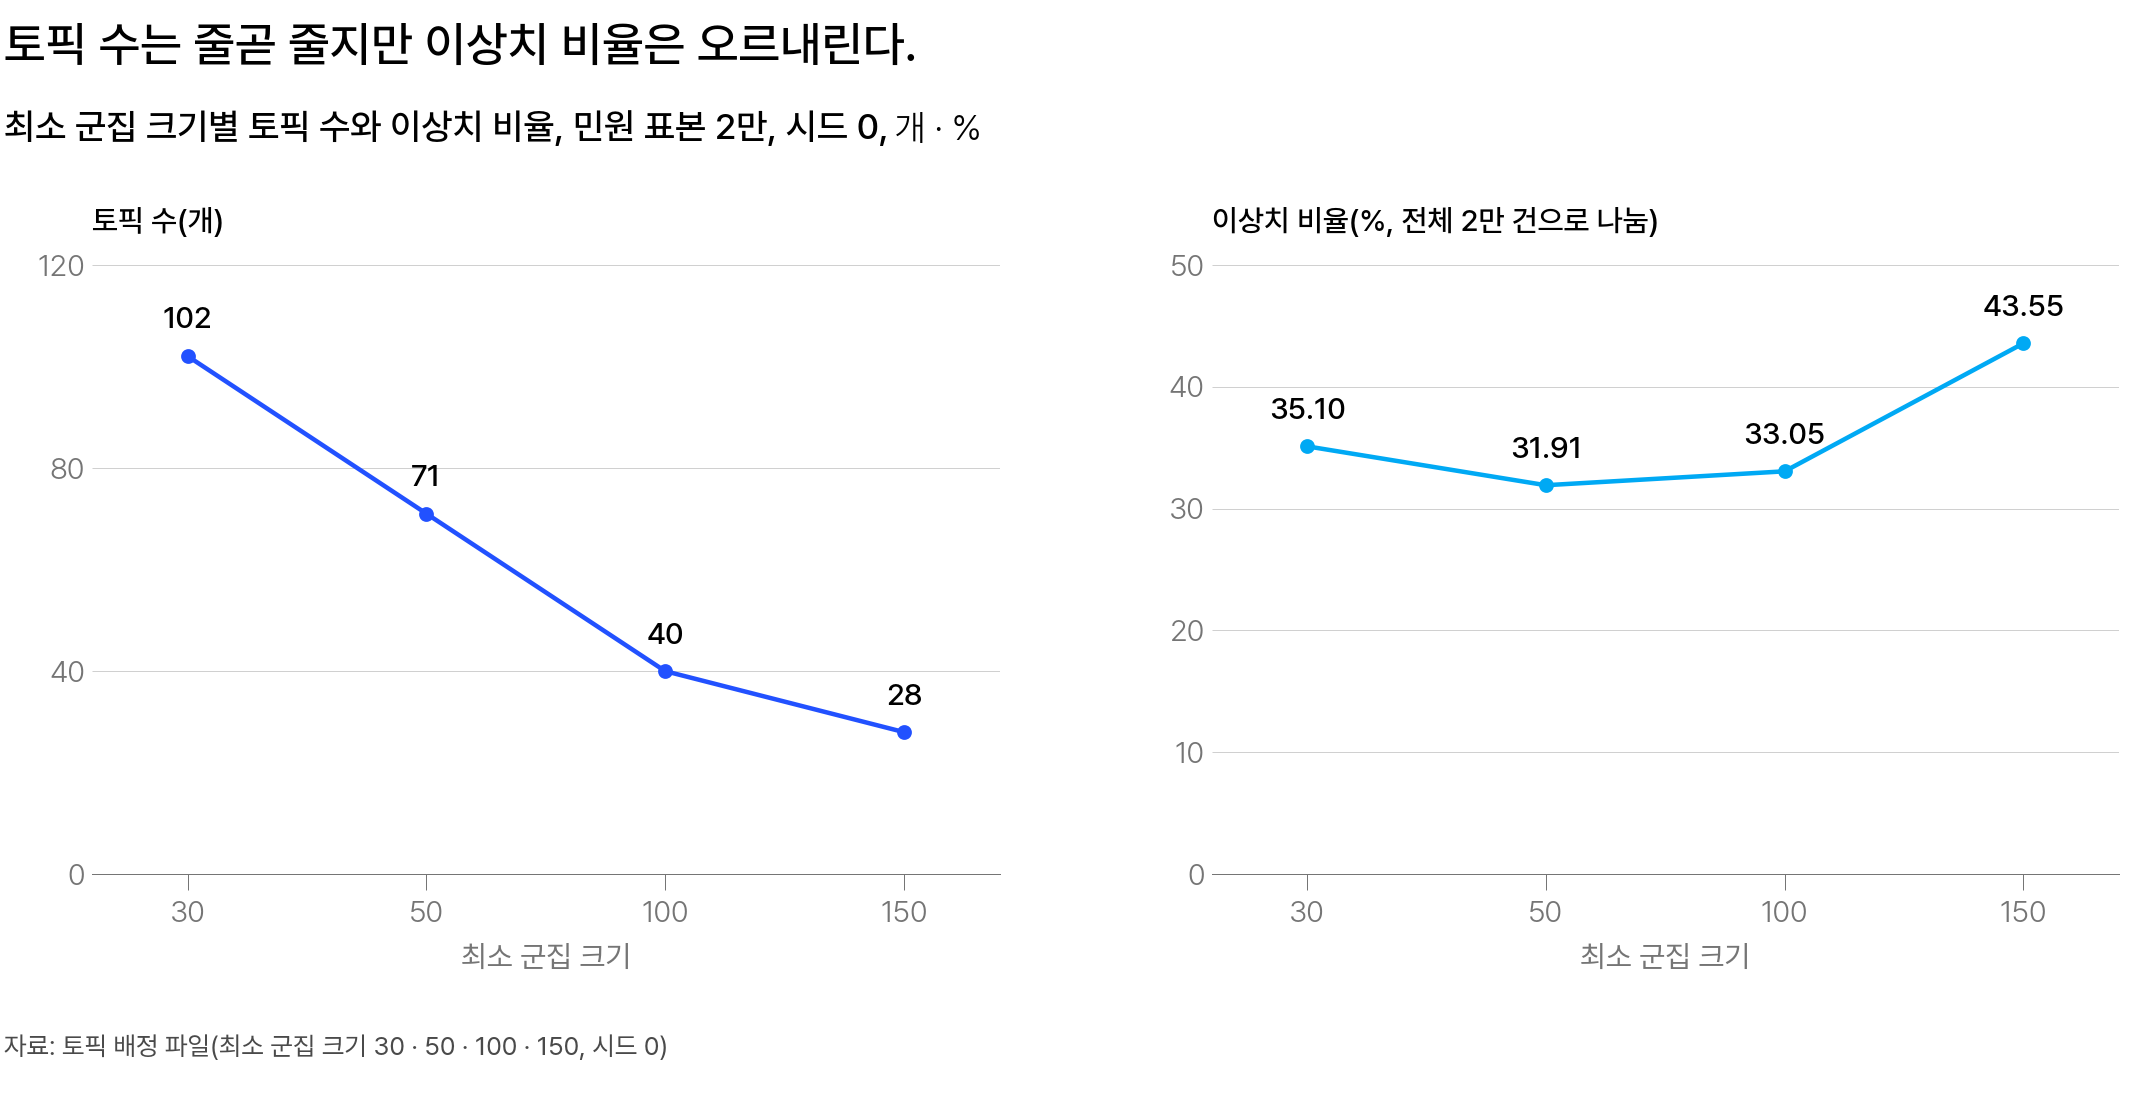

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 최소 군집 크기이고, 네 값을 같은 간격으로 놓았다. 왼쪽 토픽 수는 줄곧 준다. 오른쪽 이상치 비율은 30 에서 50 으로 갈 때 줄고, 100 에서 150 으로 갈 때 크게 는다</em></p>

**이상치 비율도 최소 군집 크기를 키울수록 늘어나나요?**

작은 군집이 이상치가 되니 이상치 비율도 늘 것 같습니다. 그런데 위 그림의 이상치 비율은 줄었다가 늘어납니다. 민원이 두 방향으로 옮겨 가기 때문입니다.

- **토픽에서 이상치로**: 최소 군집 크기에 못 미치고 이웃과 합쳐지지도 못한 군집의 민원이 이상치가 됩니다.
- **이상치에서 토픽으로**: 가까운 군집 몇 개가 하나로 합쳐지면, 그 군집들 사이에 있던 이상치 민원도 합친 토픽에 속하게 됩니다.

두 방향 가운데 옮겨 간 민원이 많은 쪽을 따라 이상치 비율이 줄거나 늘어납니다.

| 최소 군집 크기 | 이상치에서 토픽으로 | 토픽에서 이상치로 | 이상치 건수 | 이상치 비율 |
|---|---:|---:|---:|---|
| 30 → 50 | 1,656건 | 1,019건 | 7,019 → 6,382 | 줄었다 |
| 50 → 100 | 1,377건 | 1,605건 | 6,382 → 6,610 | 조금 늘었다 |
| 100 → 150 | 328건 | 2,427건 | 6,610 → 8,709 | 크게 늘었다 |

이상치에서 토픽으로 옮겨 가는 모습은 여행 민원에서 잘 보입니다.

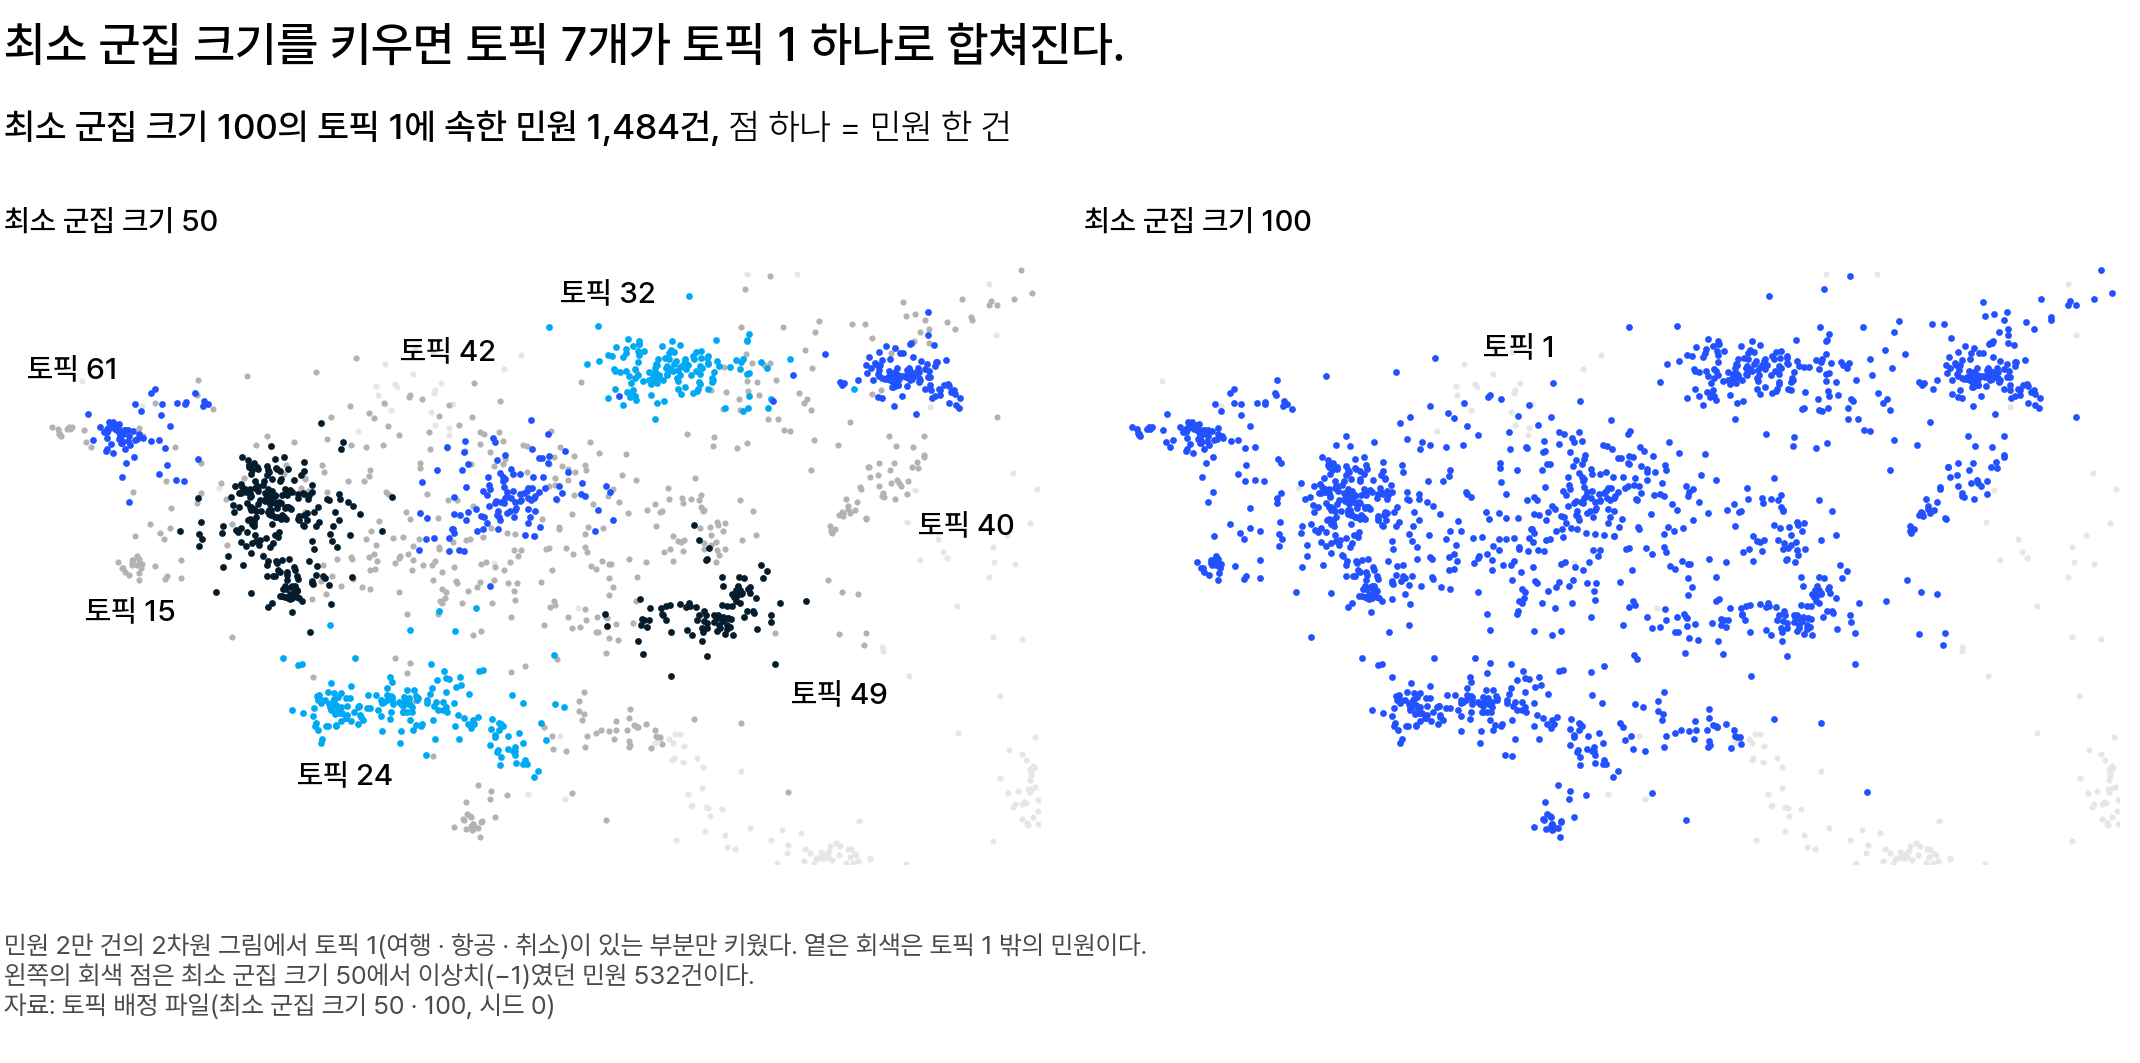

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 2차원 그림에서 토픽 1(여행 · 항공 · 취소)이 있는 부분만 키웠고, 점 하나가 민원 한 건이다. 왼쪽 최소 군집 크기 50 에서는 같은 민원이 토픽 7개와 회색 이상치로 나뉜다. 토픽 15 는 항공 · 수수료, 24 는 코로나 · 바이러스, 32 는 호텔 · 숙박 민원이다. 오른쪽 최소 군집 크기 100 에서는 모두 토픽 1 이다</em></p>

7개가 합쳐지면서 7개 사이에 있던 이상치 민원도 토픽 1 에 속하게 되었습니다. 이 민원들이 이상치에서 토픽으로 옮겨 간 쪽입니다.

**100건이 넘는 토픽은 왜 합쳐졌나요?**

7개 가운데 5개는 민원이 100건이 넘었는데도 하나로 합쳐졌습니다. 최소 군집 크기를 키우면 min_samples(밀도를 계산할 때 쓰는 이웃의 순번)도 같이 커지기 때문입니다.

민원마다 더 먼 이웃까지의 거리로 밀도를 계산해, 군집 안도 밀도가 낮게 계산됩니다. 그러면 군집 안의 밀도와 두 군집 사이 틈의 밀도가 비슷해져, 가까운 두 군집이 따로 나뉘지 않고 한 토픽이 됩니다.

<details class="lms-extra"><summary>자세히 — 최소 군집 크기 50 의 여행 관련 토픽 7개</summary>

| 최소 군집 크기 50 의 토픽 | 상위 단어 2개 | 건수 |
|---|---|---:|
| 토픽 15 | 항공 · 수수료 | 239 |
| 토픽 24 | 코로나 · 바이러스 | 182 |
| 토픽 32 | 호텔 · 숙박 | 137 |
| 토픽 42 | 여행 · 국외 | 113 |
| 다른 토픽 3개(토픽 40 · 49 · 61) | | 113 · 97 · 71 |
| 이상치 | | 532 |

최소 군집 크기 100 에서는 토픽 7개의 952건과 이상치 532건이 합쳐져 토픽 1 의 1,484건이 됩니다.

나눈 토픽과 합친 토픽 가운데 어느 쪽을 쓸지는 분석 질문에 달려 있습니다. 여행 민원 전체의 크기를 알려면 합친 쪽이, 숙박 민원만 보려면 나눈 쪽이 맞습니다.

</details>

**이상치로 옮겨 간 민원은 작은 토픽에서만 나왔나요?**

그렇지 않습니다. 최소 군집 크기를 100 에서 150 으로 키우면 민원 2,427건이 이상치로 옮겨 갑니다. 이 가운데 1,432건은 민원이 150건 이상이던 큰 토픽에서 나왔습니다.

큰 토픽에서는 주로 가장자리 민원이 이상치가 됩니다. 이상치가 된 민원이 가장 많은 토픽 2(자동차 · 차량 · 수리)에서 이 모습이 보입니다.

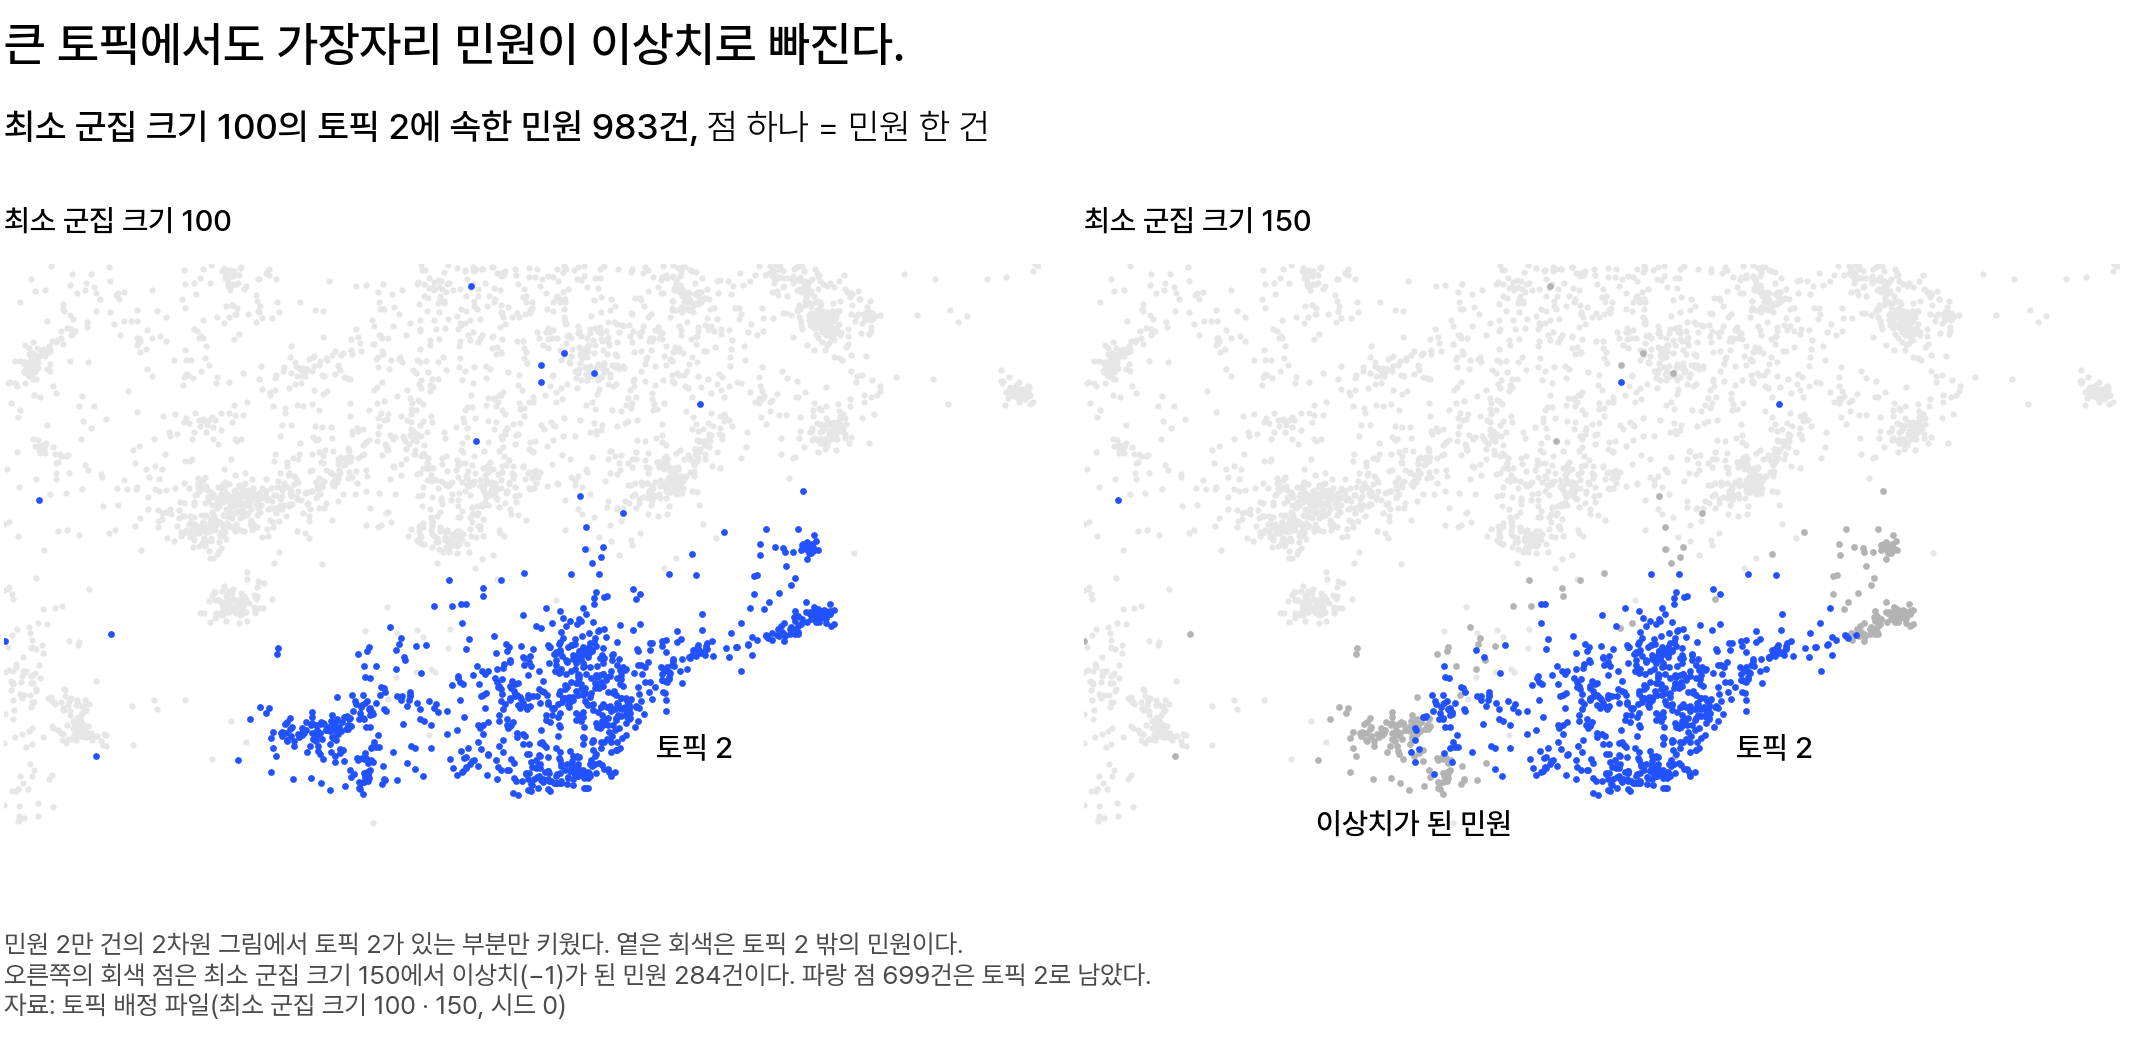

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 2차원 그림에서 토픽 2(자동차 · 차량 · 수리)가 있는 부분만 키웠다. 왼쪽 최소 군집 크기 100 에서는 모두 토픽 2 다. 오른쪽 최소 군집 크기 150 에서는 회색 점 284건이 이상치가 된다. 이상치가 된 민원은 토픽 2 의 양 끝과 가장자리에 있다</em></p>

최소 군집 크기를 150 으로 키우면 min_samples 도 150 이 됩니다. 민원마다 150번째로 가까운 이웃까지의 거리로 밀도를 계산합니다.

- **토픽 한가운데 민원**: 주변이 모두 같은 토픽이라 150번째 이웃도 가깝습니다. 밀도가 높게 계산되어 토픽에 남습니다.
- **토픽 가장자리 민원**: 한쪽에 같은 토픽 민원이 없어 150번째 이웃이 멀리 있습니다. 그 거리가 길어 밀도가 낮게 계산되고, 토픽에서 떨어져 나간 점(이상치)이 됩니다.

그래서 최소 군집 크기를 키우면 작은 토픽뿐 아니라 큰 토픽의 가장자리 민원도 이상치가 됩니다.

<details class="lms-extra"><summary>더 깊이 — 이상치로 옮겨 간 민원은 어느 토픽에서 왔는가</summary>

최소 군집 크기를 100 에서 150 으로 키울 때 이상치로 옮겨 간 2,427건을, 그 전에 속해 있던 토픽의 크기로 나눴습니다.

| 최소 군집 크기 100 에서 속해 있던 토픽 | 이상치로 옮겨 간 민원 |
|---|---:|
| 150건에 못 미치던 토픽 10개(민원 1,205건) | 995건 |
| 150건 이상이던 토픽 | 1,432건 |
| 합 | 2,427건 |

150건에 못 미치던 토픽 10개의 나머지 210건은 다른 토픽으로 옮겨 갔습니다. 최소 군집 크기 네 값의 적합 모두 min_samples 를 따로 정하지 않아, min_samples 가 최소 군집 크기와 같았습니다.

hdbscan 문서도 min_samples 가 클수록 어느 군집에도 속하지 않는 점(이상치)이 많아진다고 설명합니다.

</details>

### 최소 군집 크기는 무엇을 보고 고르는가 [필수]

최소 군집 크기는 어느 값이 옳을까요? 토픽 모델링 R 패키지 stm 의 설명서는 알맞은 토픽 수에 옳은 답이 없다고 말합니다.

> There is no right answer to the appropriate number of topics.

그래서 최소 군집 크기는 정답 하나를 찾지 않고, 아래 두 기준으로 고릅니다.

- **시드를 바꿔도 토픽 수가 같은가**: 시드마다 토픽 수가 다르면, 같은 자료로 다시 적합해도 다른 표가 나옵니다.
- **이상치 비율이 낮은가**: 이상치가 많으면 주제를 알 수 없는 민원이 많아집니다.

**시드를 바꿔도 토픽 수가 같은 최소 군집 크기는 무엇인가요?**

최소 군집 크기 6가지 값을 시드 0 · 1 · 2 로 세 번씩 적합했습니다.

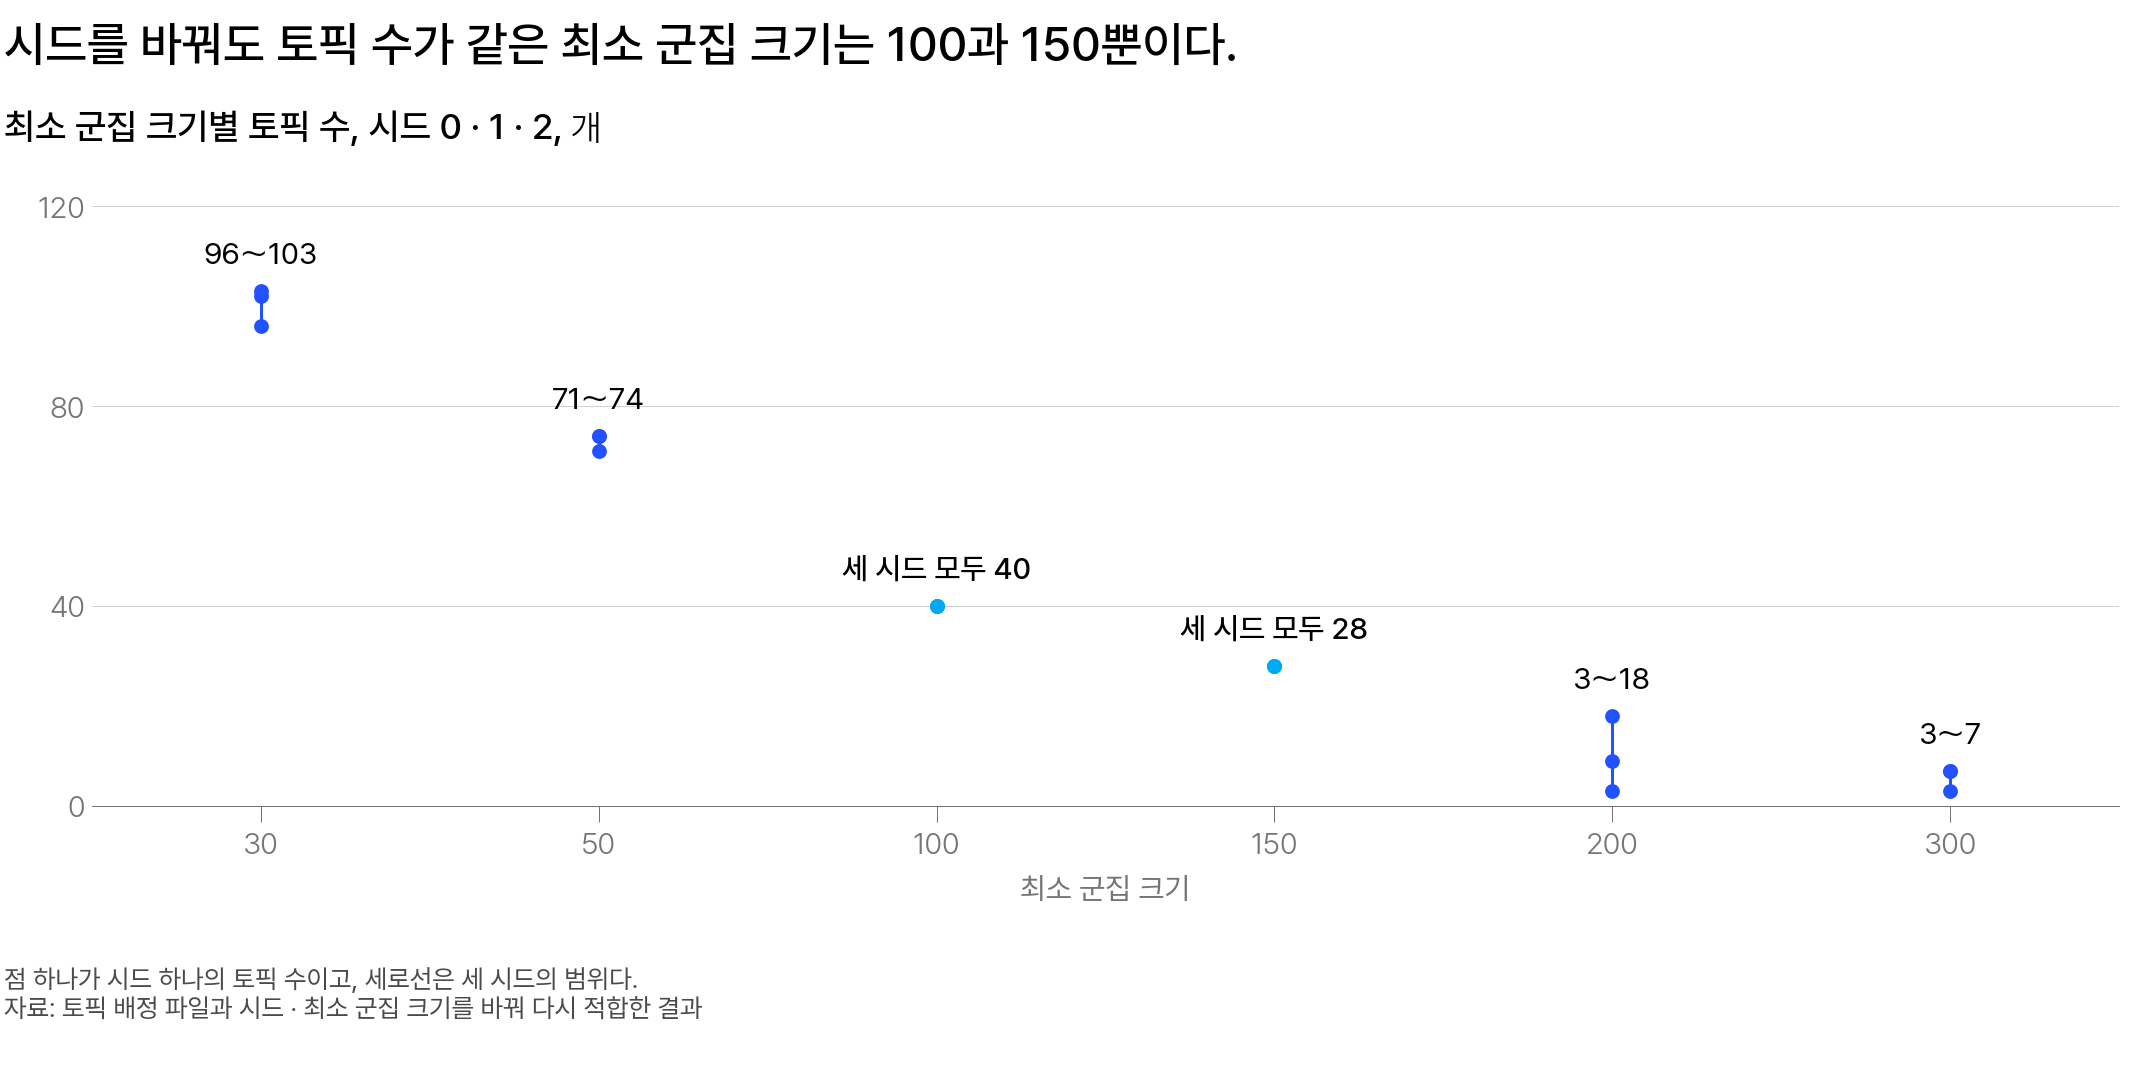

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 최소 군집 크기이고, 여섯 값을 같은 간격으로 놓았다. 세로축은 토픽 수다. 점 하나가 시드 하나의 결과이고, 세로선은 세 시드의 범위다. 최소 군집 크기 100 과 150 에서만 세 점이 40개와 28개로 겹친다(하늘색)</em></p>

최소 군집 크기 100 과 150 에서만 시드를 바꿔도 토픽 수가 같았습니다. 그런데 150 에서는 이상치 비율이 43.55% 입니다. 그래서 민원 토픽 표는 최소 군집 크기 100 으로 적합했습니다.

**시드를 바꾸면 토픽 번호도 그대로인가요?**

토픽 수가 같아도 토픽 번호까지 같지는 않습니다. 시드 0 과 시드 1 의 토픽 0 · 1 을 같은 2차원 그림에 칠했습니다.

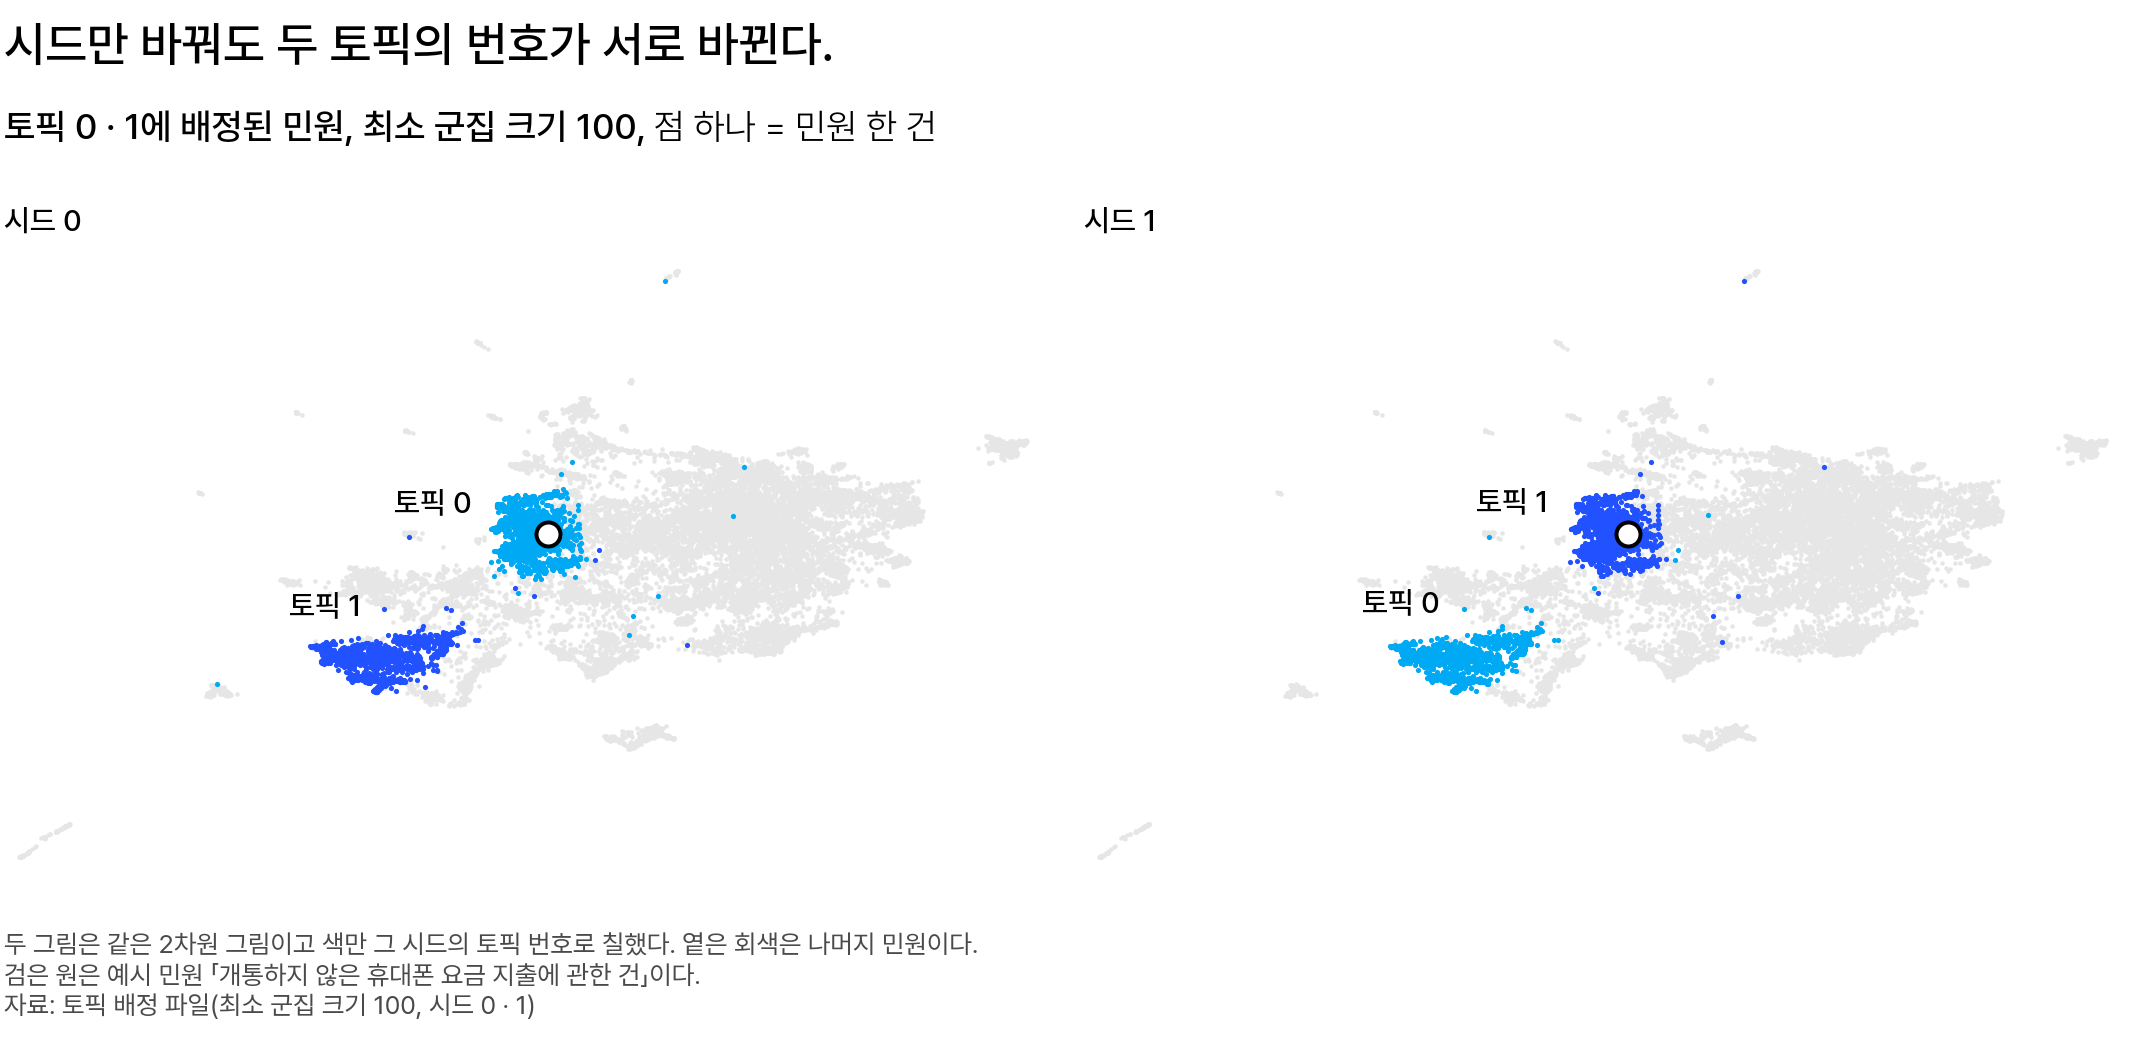

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 같은 2차원 그림을 시드 0 과 시드 1 의 토픽 번호로 칠했다. 하늘색은 토픽 0, 파랑은 토픽 1 이다. 시드 0 의 토픽 0 민원은 대부분 시드 1 에서 토픽 1 이 되고, 토픽 1 민원은 대부분 토픽 0 이 된다. 검은 원은 아래 예시 민원이다</em></p>

검은 원은 아래 민원입니다.

> 개통하지 않은 휴대폰 요금 지출에 관한 건

토픽 번호는 민원 수가 많은 순서로 매깁니다. 토픽 0(1,525건)과 토픽 1(1,484건)처럼 크기가 비슷하면, 시드에 따라 두 토픽의 번호가 서로 바뀝니다.

그래서 시드를 바꿔도 같은지는 토픽 번호가 아니라 토픽 수로 확인합니다.

<details class="lms-extra"><summary>더 깊이 — 군집 수를 점수 하나로 고르지 않는 이유</summary>

<img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_hdbscan_008.png" alt="HDBSCAN 최소 군집 크기 5, 3, 25 로 같은 점을 나눈 세 그림" width="500" height="600" />
<p align="center"><em>▲ 가로 · 세로는 점의 위치다. 같은 점을 HDBSCAN 의 min_cluster_size 5 · 3 · 25 로 나눈 세 그림이다 (출처: scikit-learn 예제 「Demo of HDBSCAN clustering algorithm」, BSD-3-Clause)</em></p>

같은 점을 최소 군집 크기 3 으로 나누면 군집이 90개로 잘게 나뉩니다. 그런데 5 와 25 에서는 둘 다 군집이 4개라, 군집 수가 값에 따라 고르게 바뀌지 않습니다. 그림의 × 표시는 어느 군집에도 속하지 않은 점(이상치)입니다.

토픽 수를 모델 점수 하나로 고르고 싶을 수도 있습니다. LDA 같은 확률 토픽 모델에는 우도(모델이 그 문서들에 매기는 확률)라는 점수가 있습니다. 그런데 Chang 외(2009) 「Reading Tea Leaves: How Humans Interpret Topic Models」는 사람에게 토픽을 읽게 하는 대규모 실험을 했습니다. 초록에 그 결론이 나옵니다.

> Surprisingly, topic models which perform better on held-out likelihood may infer less semantically meaningful topics.

학습에 쓰지 않은 문서(held-out)의 우도가 높은 모델도, 사람이 보기에는 뜻이 덜 통하는 토픽을 낼 수 있습니다. 그래서 토픽 수는 점수 하나로 고르지 않고, 시드를 바꿔도 토픽 수가 같은지와 이상치 비율을 보고 고릅니다.

</details>

**토픽 40개를 표 한 장에 어떻게 맞추나요?**

이 수업에서는 토픽 표 한 장의 항목을 12～20개로 정합니다. 그보다 많으면 주제마다 크기를 한눈에 비교하기 어렵습니다.

최소 군집 크기를 더 키워 토픽을 20개 아래로 줄이면, 시드마다 토픽 수가 크게 달라집니다. 그래서 최소 군집 크기는 100 을 그대로 쓰고, 표를 만들 때 토픽을 자르거나 합쳐 항목 수를 맞춥니다.

- **크기 순으로 자르기**: 큰 토픽 15개에 「작은 토픽 25개 합계」와 이상치를 더해 항목 17개로 만듭니다.
- **같은 주제끼리 합치기**: 상위 단어와 원문을 읽어 같은 주제인 토픽끼리 합치고, 이상치를 더한 항목을 20개 안팎으로 만듭니다. 합친 토픽의 상위 단어는 c-TF-IDF 를 다시 계산해 구합니다.

합친 기준과 합친 토픽 번호를 분석팀 기록에 남기지 않으면, 다른 사람은 같은 표를 다시 만들 수 없습니다. 두 방법 가운데 무엇을 쓸지는 표로 답할 질문에 따라 다릅니다.

<div class="lms-summary">

**정리**

최소 군집 크기를 키우면 토픽 수는 줄지만, 이상치 비율은 두 방향으로 옮겨 간 민원 수에 따라 줄기도 하고 늘기도 합니다. 최소 군집 크기는 시드를 바꿔도 토픽 수가 같은지와 이상치 비율을 확인해 고릅니다.

**할 일**

- 최소 군집 크기를 바꿔 볼 때는 토픽 수와 이상치 비율을 같이 비교합니다
- 토픽이 표 한 장에 넘치면 크기 순으로 자르거나 같은 주제끼리 합치고, 합친 기준은 분석팀 기록에 남깁니다

최소 군집 크기 100 은 시드 세 번 모두 토픽 40개가 나왔고, 이상치는 민원 3건 가운데 1건입니다.

</div>

> **[문제] 최소 군집 크기와 이상치 비율**
>
> 최소 군집 크기 30·50·100·150 에서 이상치 비율은 35.10·31.91·33.05·43.55% 였습니다. 「최소 군집 크기를 키우면 이상치 비율도 늘 커진다」는 말이 맞는지 위 수로 판단해 보세요. 그리고 최소 군집 크기를 100 에서 150 으로 키웠을 때 이상치 비율이 크게 늘어난 이유를 적어 보세요. 토픽과 이상치 사이를 옮겨 간 민원의 두 수와, 옮겨 간 민원이 작은 토픽에서만 나왔는지를 함께 적습니다.

## 4. 토픽 표는 어떻게 읽는가

토픽 표를 받으면 무엇부터 확인할까요?

먼저 토픽 비율의 분모를 확인합니다. 토픽 비율은 「접수된 민원 가운데 몇 % 가 이 주제인가」에 답하는 수라서, 분모는 이상치까지 포함한 민원 2만 건입니다. 이상치를 빼고 나누면 모든 토픽이 같은 배수만큼 커 보이고, 민원 3건 가운데 1건이 표에서 사라집니다.

### 토픽 비율은 무엇으로 나누는가 [필수]

이상치는 이름이 없는 민원이라, 표에서 빼고 토픽 비율의 합을 100% 로 맞추고 싶어질 수 있습니다. 그런데 이상치를 빼면 토픽마다 건수는 그대로이고 분모만 줄어듭니다.

**민원 10건이면 비율이 어떻게 달라지나요?**

민원 10건이 토픽 A 4건, 토픽 B 3건, 이상치 3건으로 나뉘었습니다.

| 항목 | 건수 | 전체 10건으로 나눈 비율 | 이상치를 뺀 7건으로 나눈 비율 |
|---|---:|---:|---:|
| 토픽 A | 4 | 40% | 57% |
| 토픽 B | 3 | 30% | 43% |
| 이상치 | 3 | 30% | 표에서 빠짐 |

- 이상치를 빼고 나누면 건수는 그대로이고 분모만 10 에서 7 로 줄어, 토픽 A 는 40% 에서 57% 로 커 보입니다. 토픽 B 도 30% 에서 43% 로, 두 토픽 모두 10 ÷ 7 = 1.43배가 됩니다.
- 토픽 A 와 B 만 더하면 100% 가 되지만, 민원 10건 가운데 3건은 표에서 보이지 않습니다.

**토픽 비율** 은 토픽에 속한 민원 수를 이상치까지 포함한 전체 민원 수로 나눈 값입니다. 문서 비율을 배울 때 전체 문서 수로 나눈 것과 같습니다.

$$
p_k = \frac{n_k}{N}
$$

- $p_k$: 토픽 $k$ 의 비율
- $n_k$: 토픽 $k$ 에 속한 민원 수
- $N$: 이상치를 포함한 전체 민원 수(분모)

**민원 2만 건에서는 얼마나 커 보이나요?**

민원 2만 건 가운데 이상치가 6,610건이라, 이상치를 빼면 분모가 13,390건으로 줄어듭니다.

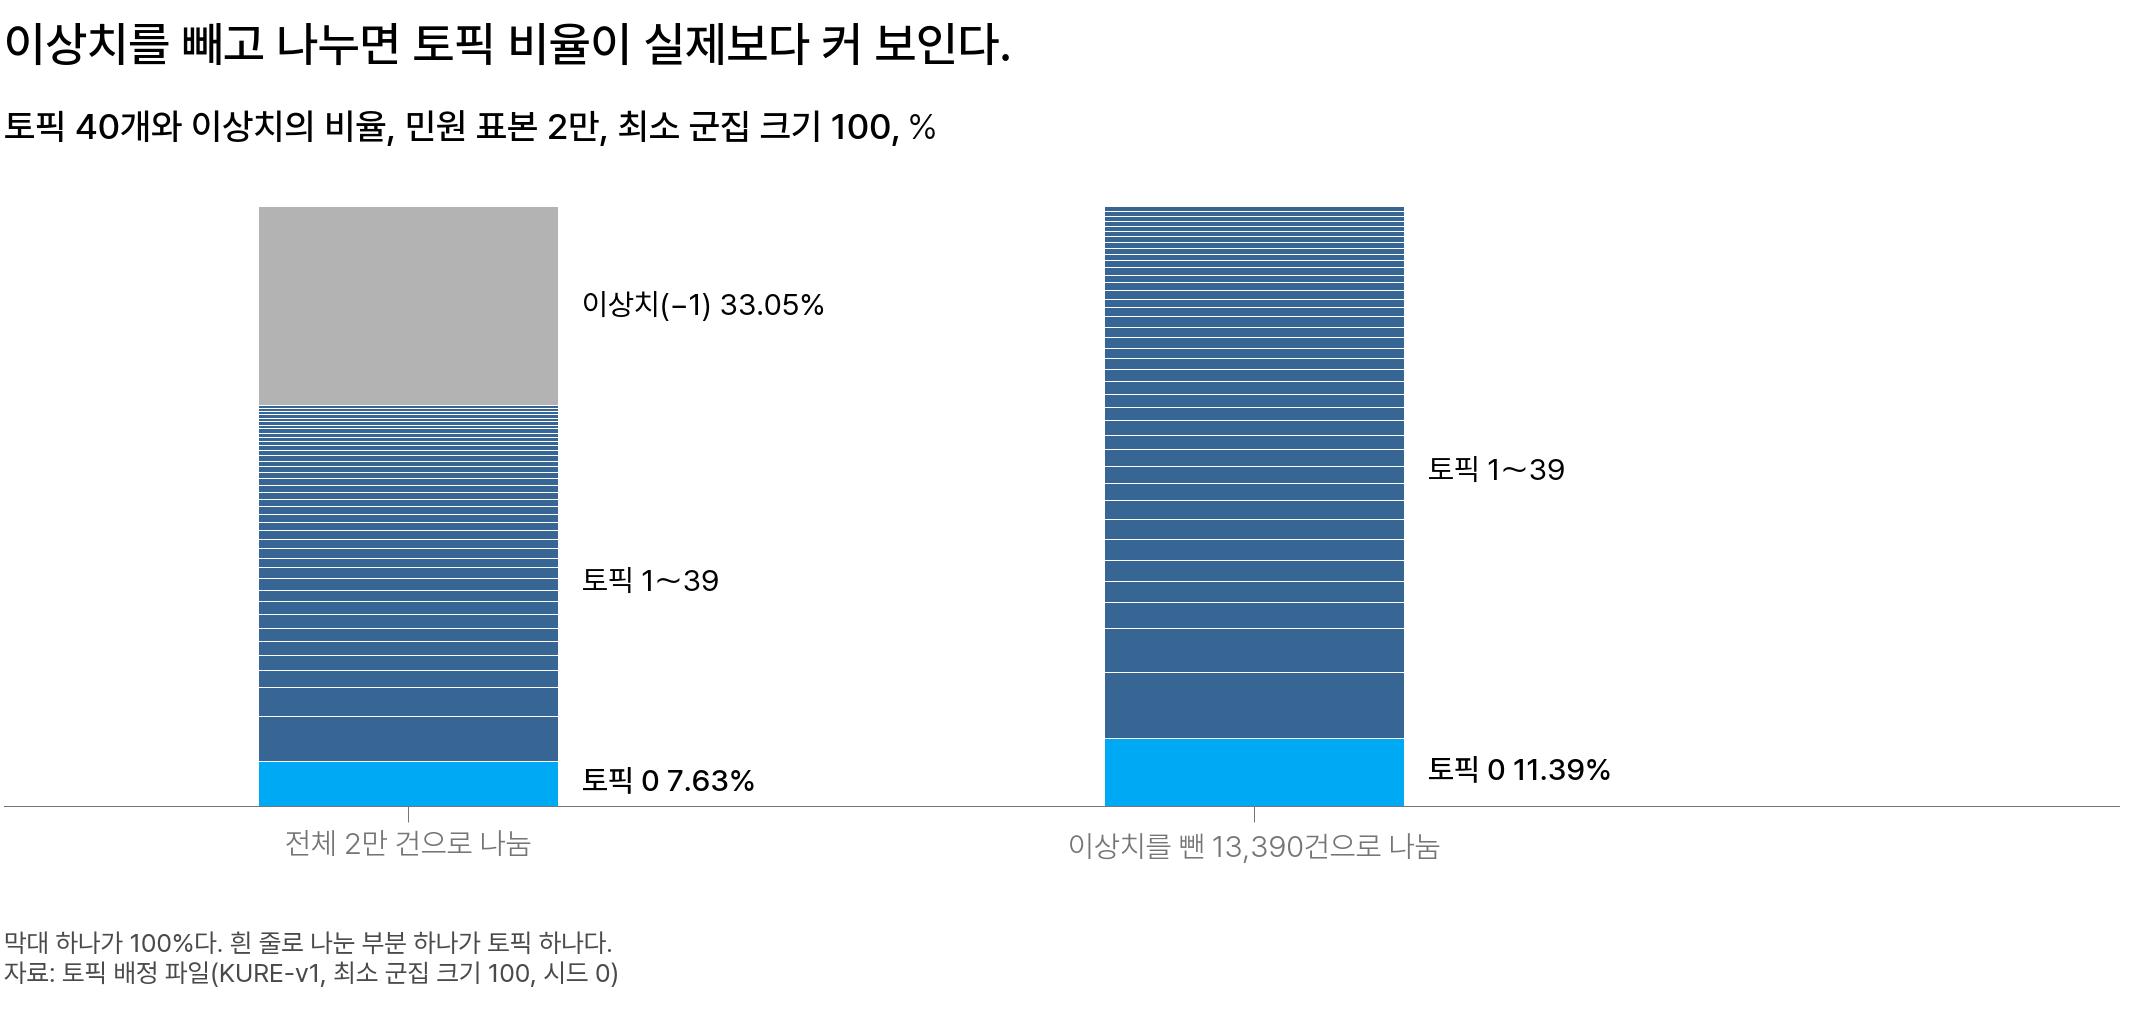

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 막대 하나가 100% 이고, 흰 줄로 나눈 부분 하나가 토픽 하나다. 왼쪽은 전체 2만 건으로 나눈 비율이고, 회색 이상치가 가장 큰 부분이다. 오른쪽은 이상치를 뺀 13,390건으로 나눈 비율이고, 하늘색 토픽 0 이 7.63% 에서 11.39% 로 커진다</em></p>

아래 셀은 두 막대의 비율을 토픽 40개의 민원 수로 직접 계산합니다. 같은 민원 수를 두 분모로 나눕니다.

In [ ]:
# 토픽 40개와 −1 의 민원 수(최소 군집 크기 100, 시드 0) — 같은 분자를 두 분모로 나눈다
sizes = [1525, 1484, 983, 566, 478, 472, 451, 450, 427, 387, 376, 366, 330, 322,
         296, 296, 279, 267, 242, 238, 236, 234, 232, 198, 196, 183, 183, 168,
         167, 153, 141, 137, 137, 123, 120, 115, 109, 108, 108, 107]    # 토픽 0～39 의 민원 수
n_out = 6610                                                            # 이상치(−1) 민원 수

for name, denom in [("이상치를 포함한 분모", sum(sizes) + n_out), ("이상치를 뺀 분모", sum(sizes))]:
    share = [100 * n / denom for n in sizes]                           # 토픽마다 비율(%)
    print(f"{name} {denom:,}: 토픽 0 {share[0]:.3f}% · 토픽 40개 합 {sum(share):.3f}%")
print(f"모든 토픽에 똑같이 곱해지는 배수: {(sum(sizes) + n_out) / sum(sizes):.4f}")

출력처럼 모든 토픽이 같은 배수만큼 커지고 토픽 40개의 합은 100% 가 됩니다. 배수는 전체 20,000건 ÷ 이상치를 뺀 13,390건 ≈ 1.494 입니다.

이상치를 빼고 나눈 표를 받은 사람은 토픽 0 이 민원 전체의 11.39% 라고 말하게 됩니다. 실제로는 접수된 민원 2만 건 가운데 7.63% 입니다. 분모가 표에 없으면, 표를 보는 사람은 이상치를 뺀 비율인지 알 수 없습니다.

<details class="lms-extra"><summary>자세히 — 모든 토픽에 같은 배수가 곱해지는 이유</summary>

이상치를 빼고 나눈 토픽 $k$ 의 비율을 $p'_k$ 로 씁니다. 분모는 전체 민원 수 $N$ 에서 이상치 민원 수 $n_{-1}$ 을 뺀 값입니다.

$$
p'_k = \frac{n_k}{N - n_{-1}}
$$

분수에 $N \div N = 1$ 을 곱해도 값은 같습니다. 곱한 뒤 $n_k / N$ 과 $N / (N - n_{-1})$ 로 나눠 묶습니다.

$$
p'_k = \frac{n_k}{N} \times \frac{N}{N - n_{-1}}
$$

앞의 $n_k / N$ 은 원래 비율이므로 $p_k$ 를 대입합니다.

$$
p'_k = p_k \times \frac{N}{N - n_{-1}}
$$

배수 $N/(N - n_{-1})$ 에는 토픽 번호 $k$ 가 없습니다. 그래서 모든 토픽에 같은 배수가 곱해집니다.

```text
배수 = 20,000 ÷ (20,000 − 6,610)
     = 20,000 ÷ 13,390
     = 1.494
```

토픽 0 은 1,525 ÷ 13,390 = 11.39% 로, 건수는 그대로이고 분모만 줄었습니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 최소 군집 크기마다 달라지는 배수</summary>

이상치를 빼고 나누면 문제가 하나 더 생깁니다. 최소 군집 크기를 바꾸면 이상치 비율이 바뀌고, 비율이 커지는 배수도 함께 바뀝니다. 그러면 두 표의 비율이 다를 때 토픽이 커진 것인지 분모가 줄어든 것인지 표만 보고는 구분할 수 없습니다.

배수는 1 ÷ (1 − 이상치 비율)이라 이상치 비율만으로 정해집니다. 이상치가 없으면 배수는 1 입니다.

| 최소 군집 크기 | 이상치 비율 | 배수 |
|---|---:|---:|
| 50 | 31.91% | 1.469 |
| 100 | 33.05% | 1.494 |
| 150 | 43.55% | 1.771 |

예를 들어 최소 군집 크기 50 과 150 의 표를 둘 다 이상치를 빼고 나누면, 건수가 같은 토픽도 150 쪽 비율이 약 1.2배 큽니다.

전체 2만 건으로 나누면 최소 군집 크기를 바꿔도 분모가 그대로라, 설정이 다른 두 표를 비교할 수 있습니다.

BERTopic 에는 이상치 민원을 가장 가까운 토픽에 다시 배정하는 기능(`reduce_outliers`)도 있습니다. 이 기능을 쓰면 모든 토픽 비율이 달라지므로, 이 기능을 쓴 표와 비교하려면 다시 배정한 방법까지 알아야 합니다. 민원 토픽 표는 이 기능을 쓰지 않았습니다.

</details>

### 이상치에는 어떤 민원이 있는가 [필수]

이상치 민원 6,610건도 토픽 문서 하나로 합쳐 c-TF-IDF 를 계산하면 상위 단어는 반품 · 구입 · 환불 · 구매 · 교환입니다. 상위 단어만 보면 이상치에 「기타 불만」이나 「환불 · 반품 기타」 같은 이름을 짓고 싶어집니다.

**무작위로 고른 이상치 민원은 어떤 이야기인가요?**

이상치 민원에서 무작위로 3건을 골랐습니다(시드 0).

| 민원 제목 | 주제 |
|---|---|
| 시계 구매후 수리 보냈으나 수리하지않고 다시 보냈으나 하자 | 시계 수리 |
| led 간판 중도 해지 | LED 간판 해지 |
| 화장품 반품 거부하여 문의 | 화장품 반품 |

3건의 주제가 모두 다릅니다. 이상치는 최소 군집 크기 100 을 채운 군집에 속하지 못한 민원의 모음이기 때문입니다. 여러 주제의 민원이 함께 있어서, 어느 물건에나 나오는 흔한 말이 상위 단어가 됩니다.

밀도 기반 군집화의 작은 예에서도 이상치는 한곳에 모이지 않습니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/0/05/DBSCAN-density-data.svg" alt="파란 군집 하나, 초록 초승달 하나, 그 바깥 여러 곳에 따로 떨어진 회색 점들" width="400" height="403" />
<p align="center"><em>▲ 가로 · 세로는 점의 위치다. 밀도 기반 군집화 결과, 파란 군집과 초록 초승달 바깥에 회색 점 수십 개가 여러 곳에 따로 떨어져 있다 (출처: Wikimedia Commons 「DBSCAN-density-data.svg」, Chire, CC BY-SA 3.0)</em></p>

민원의 이상치도 그림의 회색 점처럼 여러 곳에 따로 떨어져 있어, 한 주제가 아닙니다. 그래서 이상치에는 토픽 이름을 짓지 않습니다. 이름을 지으면 여러 주제가 한 주제처럼 보입니다.

> **[문제] 필수 머신러닝의 DBSCAN 은 초승달 데이터 400점에서 어느 군집에도 속하지 않은 점을 −1 로 분류했습니다. 민원 토픽 표의 이상치 6,610건을 맞게 이해한 것은 무엇일까요?**
>
> 1. 「기타 불만」이라는 한 주제의 민원이다
> 2. 100건 이상 모인 군집에 속하지 못한 민원이라 서로 다른 주제가 함께 있다
> 3. 임베딩 계산에 실패한 민원이다
> 4. 다시 적합하면 모두 토픽 0 으로 들어간다

### 토픽 이름은 어떻게 정하는가 [필수]

토픽 표를 받으면 건수가 많은 토픽부터 상위 단어를 보고 이름 후보를 정합니다.

| 토픽 | 비율 | c-TF-IDF 상위 단어 5개 | 상위 단어로 정한 이름 후보 |
|---:|---:|---|---|
| 0 | 7.63% | 개통 · 요금 · 휴대폰 · 철회 · 인터넷 | 아래에서 원문까지 읽고 정함 |
| 1 | 7.42% | 여행 · 항공 · 취소 · 예약 · 코로나(COVID-19) | 코로나 때문에 취소한 여행 · 항공 예약 |
| 2 | 4.92% | 자동차 · 차량 · 수리 · 중고 · 사고 | 자동차 수리와 중고차 사고 |
| 3 | 2.83% | 헬스장 · 헬스 · 중도 · 해지 · 환불 | 헬스장 중도 해지와 환불 민원 |
| 4 | 2.39% | 정수기 · 렌탈 · 코웨이 · 비데 · 지연 | 정수기 · 비데 렌탈과 지연 |

토픽 1～4 의 이름은 상위 단어만 보고 정한 후보입니다.

**상위 단어만 보고 이름을 정하면 왜 안 되나요?**

- 상위 단어는 c-TF-IDF 점수가 높은 명사 몇 개뿐입니다. 민원들이 실제로 다루는 주제는 이보다 넓을 수 있습니다.
- 반대 뜻의 민원 제목도 같은 명사를 씁니다. 두 민원이 한 토픽에 함께 있어도 상위 단어로는 구분할 수 없습니다.

반대 뜻의 민원이 한 토픽에 속하는 이유는 문장 임베딩을 배울 때 본 예와 같습니다. KURE-v1 의 코사인은 반대 뜻 문장이 같은 뜻 문장보다 높았습니다.

| 기준 문장 「배송이 정말 빨라요」와 비교한 문장 | 코사인 |
|---|---:|
| 반대 뜻 「배송이 정말 느려요」 | 0.822 |
| 같은 뜻 「택배가 하루 만에 도착했어요」 | 0.761 |

기준 문장과 반대 뜻 문장은 벡터가 가까워 한 토픽에 속할 수 있습니다. 두 문장의 명사는 「배송」 하나뿐이라 상위 단어에도 「배송」만 남습니다. 그래서 상위 단어로 정한 이름은 후보로만 씁니다.

**토픽 0 의 이름은 무엇부터 읽고 정하나요?**

먼저 대표 문서 한 건을 읽습니다. 토픽 0 의 대표 문서는 아래 민원 제목이고, 상위 단어 개통 · 요금 · 휴대폰이 모두 있습니다.

> 개통하지 않은 휴대폰 요금 지출에 관한 건

다만 대표 문서 한 건만으로는 부족합니다. 대표 문서는 상위 단어에 가장 잘 맞는 민원이라서, 토픽이 실제보다 한 주제처럼 보일 수 있습니다. 그래서 토픽 0 에서 무작위로 3건을 더 읽었습니다.

| 민원 제목 | 상위 단어 5개에 없는 내용 |
|---|---|
| 휴대폰 교체후 발생한 과다 위약금 피해건. | 위약금 |
| 기기값 과다청구로인한철회요청 | 기기값 |
| 이동전화 관리감독 기관문의 | 감독 기관 문의 |

3건 모두 휴대폰 · 이동전화 이야기이고 반대 뜻인 민원은 없지만, 주제는 상위 단어보다 넓습니다. 토픽 0 의 이름 후보는 「휴대폰 · 통신 민원」입니다.

토픽 이름은 아래 순서로 정합니다.

```text
상위 단어 5개 → 이름 후보
→ 대표 문서 한 건: 상위 단어가 실제 민원 제목에 함께 나오는가
→ 무작위 원문 여러 건: 주제가 더 넓은가, 반대 뜻인 민원이 함께 있는가
→ 더 읽은 민원 대부분에 맞으면 이름으로 쓴다
```

<details class="lms-extra"><summary>자세히 — 대표 문서를 고르는 계산</summary>

토픽의 c-TF-IDF 벡터는 단어마다 c-TF-IDF 점수를 하나씩 나열한 목록입니다. 토픽 0 이면 단어 3,080종의 점수 3,080개입니다.

민원 제목 하나도 같은 방법으로 점수 목록을 만듭니다. 그 민원 제목에 단어가 나온 횟수를 명사 수로 나누고 같은 로그 항 $\log(1 + A/f_t)$ 를 곱합니다.

두 점수 목록의 코사인이 가장 큰 민원이 대표 문서입니다. 코사인은 문장 임베딩을 배울 때 두 벡터를 비교한 방법과 같습니다.

</details>

<div class="lms-summary">

**정리**

토픽 비율은 이상치까지 포함한 전체 민원 수로 나눕니다. 이상치를 빼고 나누면 모든 토픽이 같은 배수만큼 커 보이고, 민원 3건 가운데 1건이 표에서 사라집니다. 토픽 이름은 상위 단어로 후보를 정하고 원문으로 확인합니다.

**할 일**

- 표를 만든 뒤 토픽 비율의 합과 이상치 비율을 더해 100% 가 되는지 확인합니다
- 이상치 항목에 「기타 불만」 같은 이름이 있으면 「이상치(이름 없음)」로 바꿉니다
- 토픽 비율만 더해 100% 가 되면 이상치를 뺀 분모이므로, 2만 건으로 다시 나눕니다

이상치는 여러 주제의 민원이 함께 있어, 이름 없이 「이상치(이름 없음)」 항목이 됩니다.

</div>

> **[문제] 토픽 1 비율의 두 분모**
>
> 민원 표본 20,000건에서 토픽 1(여행·항공·취소)은 1,484건, 이상치는 6,610건입니다. 토픽 1 의 토픽 비율을 분모와 함께 적고, 이상치를 뺀 분모로 나눈 값도 적어 보세요.

## 5. 정리와 팀 라운드

민원 토픽 표로 CX 팀(고객 경험을 맡은 팀)에 무엇을 알릴까요?

주제마다 민원이 얼마나 되는지와, 어느 주제에도 속하지 않은 민원이 얼마인지를 쉬운 말로 알립니다.

### 토픽 표를 보내기 전에 무엇을 확인하는가 [필수]

토픽 표를 CX 팀장에게 보내기 전에 분모 · 상위 단어 · 원문을 차례로 확인합니다.

| 항목 | 확인 내용 | 고치는 방법 | 토픽 0 의 결과 |
|---|---|---|---|
| 분모 | 비율의 분모가 이상치를 포함한 전체 민원 수인가 | 전체 민원 수로 다시 나눈다 | 20,000건으로 나눠 맞다 |
| 상위 단어 | 상위 단어 5개가 한 주제로 보이는가 | 주제와 상관없는 말이 있으면 불용어 목록을 고쳐 다시 계산한다 | 통신 서비스 한 주제로 보인다 |
| 원문 | 무작위로 고른 민원 여러 건이 상위 단어보다 넓은 주제인지, 반대 뜻인 민원이 함께 있는지 | 이름은 후보로만 쓰고 원문을 더 읽는다 | 반대 뜻은 없지만 위약금 · 기기값처럼 더 넓은 주제가 있다 |

토픽 0 의 이름은 아직 후보 「휴대폰 · 통신 민원」입니다.

**같은 표를 다시 만들려면 무엇을 알아야 하나요?**

표를 만든 설정은 분석팀 기록에 남깁니다. 이 기록이 없으면 다른 사람은 같은 표를 다시 만들 수 없습니다.

- 문장 인코더: KURE-v1
- UMAP 의 이웃 수: 15
- 시드: 0
- 최소 군집 크기: 100
- 불용어 목록: 문의 · 요청 등 9개

<details class="lms-extra"><summary>더 깊이 — 단계마다 바꿔 쓸 수 있는 방법</summary>

BERTopic 은 단계마다 다른 방법을 쓸 수 있습니다.

<img src="https://maartengr.github.io/BERTopic/algorithm/modularity.svg" alt="단계마다 바꿔 쓸 수 있는 방법을 가로로 나열한 그림" width="640" height="292" />
<p align="center"><em>▲ 단계마다 바꿔 쓸 수 있는 방법. 차원 축소 단계에 UMAP·PCA·TruncatedSVD, 군집 단계에 HDBSCAN·k-Means·BIRCH 가 있다 (출처: BERTopic 문서 「The Algorithm」, Maarten Grootendorst, MIT)</em></p>

예를 들어 UMAP 대신 PCA 를, HDBSCAN 대신 K-Means 를 쓸 수 있습니다. K-Means 를 쓰면 이상치가 없어집니다. 대신 모든 민원이 가장 가까운 토픽에 배정되어 모든 토픽 비율이 달라집니다.

</details>

**CX 팀에는 어떤 결론을 보내나요?**

위 세 가지를 확인한 뒤 CX 팀에 보내는 결론입니다.

> 2020년 민원 가운데 무작위로 고른 2만 건을, 뜻이 비슷한 민원끼리 주제 40개로 나눴습니다.
>
> 가장 큰 두 주제는 개통 · 요금 · 휴대폰(7.63%)과 여행 · 항공 · 취소(7.42%)로 크기가 거의 같습니다. 가장 큰 주제도 10% 가 되지 않아, 민원이 한두 주제에 몰려 있지 않습니다.
>
> 개통 · 요금 · 휴대폰 주제는 무작위로 고른 원문 3건을 읽고 「휴대폰 · 통신 민원」이라는 이름 후보를 골랐습니다. 여행 · 항공 · 취소 주제의 이름은 아직 원문을 읽지 않은 후보입니다.
>
> 민원 3건 가운데 1건(33.05%)은 어느 주제에도 속하지 않았고, 「기타 불만」 한 주제가 아닙니다. 모든 비율은 이 민원까지 포함한 2만 건으로 나눴습니다.

<div class="lms-summary">

**정리**

토픽 표는 분모 · 상위 단어 · 원문을 확인한 뒤에 보냅니다. CX 팀에는 주제와 건수 · 비율을 쉬운 말로 보내고, 모델 이름과 설정은 보내지 않습니다.

**할 일**

- 토픽 수와 이상치 비율이 나온 설정(최소 군집 크기 · 시드)을 분석팀 기록에 남깁니다
- 다시 적합한 표끼리는 토픽 번호가 아니라 토픽 수와 이상치 비율로 비교합니다

민원 토픽 표는 최소 군집 크기 100 에서 나온 토픽 40개와 이상치를 모두 2만 건으로 나눈 표입니다.

</div>

### 팀 라운드: CX 팀장에게 올릴 민원 토픽 표 [필수]

아래 질문의 답은 수업에서 팀이 함께 정합니다. 지금은 자기 답과 근거만 적어 두면 됩니다.

각자 답과 확신도(1～5)를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거 세 문장을 나눠 토론한 뒤 팀이 답 하나로 모아 제출합니다.

> **[문제] 팀 라운드: CX 팀장에게 올릴 민원 토픽 표**
>
> CX 팀장이 다음 분기에 무엇부터 고칠지 정하려고, 2020년 1～10월 민원 2만 건의 토픽 표를 한 장(항목 12～20개)으로 원합니다. 분석팀은 시드 0 에서 최소 군집 크기만 100 · 150 으로 바꿔 적합했고, 시드 1 · 2 로도 다시 적합해 토픽 수를 확인했습니다.
> 
> - **토픽 수(시드 0 · 1 · 2)와 이상치 비율(시드 0)** 100 은 40 · 40 · 40개와 33.05%, 150 은 28 · 28 · 28개와 43.55%
> - **100 → 150 에서 옮겨 간 민원** 토픽에서 이상치로 2,427건(그중 1,432건은 150건 이상이던 토픽에서), 이상치에서 토픽으로 328건
> - **100 의 크기 순 상위 15개(토픽 0～14)** 가장 큰 토픽 0 은 1,525건, 토픽 3(4위)은 566건, 토픽 14(15위)와 토픽 15(16위)는 둘 다 296건
> - **100 의 나머지 25개(토픽 15～39)** 합계 4,477건(22.39%), 그 가운데 1위 단어가 냉장고 · 노트북 · 에어컨인 토픽 20 · 21 · 25 는 합해서 653건
> 
> 팀 안에서 의견이 3가지로 나뉘었습니다.
> 
> - **관점 A: 100 으로 적합하고, 상위 15개에 「작은 토픽 25개 합계」와 이상치를 더해 항목 17개로 표를 만든다.** 자르는 기준이 건수뿐이라 같은 파일이면 누가 만들어도 같은 표가 나오고, 다음 분기에도 같은 방식을 그대로 쓸 수 있다.
> - **관점 B: 150 으로 적합한 토픽 28개로 표를 만든다.** 시드를 바꿔도 28개이고 모두 150건 이상이라 토픽마다 건수가 충분하며, 한 장에 넘치는 토픽은 같은 주제끼리 합친다. 이상치도 분모에 포함해 맨 아래 항목으로 남기므로 비율은 틀리지 않는다.
> - **관점 C: 100 으로 적합하고, 상위 단어와 원문을 읽어 같은 주제인 토픽끼리 합친다.** 이상치를 더해 항목은 20개 안팎이고, 합친 기준과 합친 토픽 번호는 분석팀 기록으로 남긴다. 이상치를 뺀 모든 항목이 주제 하나라 주제의 크기 순서를 바로 읽을 수 있다.
> 
> 자기 입장 하나와 근거 세 문장, 다음에 확인할 일 하나, 그리고 확신도를 정해 오세요.